# Chuẩn bị dữ liệu dịch máy EN–VI: làm sạch và gộp MTet + PhoMT + IWSLT'15

**Mục tiêu**: gộp 3 nguồn song ngữ Anh–Việt về một định dạng thống nhất, làm sạch bằng các luật có thể giải thích và đo đếm được, rồi xuất `train/valid/test` (`.en`, `.vi`, `.parquet`) vào `data/clean/`.

**Quy trình tổng quát**

1. Nạp dữ liệu thô, kiểm tra cấu trúc từng nguồn.
2. EDA dữ liệu thô: độ dài, tỉ lệ độ dài, tỉ lệ ký tự dấu tiếng Việt, từ đó chọn ngưỡng.
3. Bộ *detokenizer* dùng chung cho cả 3 nguồn (cả 3 đều bị tokenize ở mức khác nhau).
4. Sửa/loại lỗi mã hoá (mojibake) rồi các luật lọc (mỗi luật là một hàm trả về mask giữ lại: ngôn ngữ, sao chép EN≈VI, số lệch, nháy kép lẻ, thiếu nội dung, ...) + `RuleLog` ghi số dòng bị loại.
5. Chạy toàn bộ pipeline, MTet xử lý từng shard để không tràn RAM.
6. Tổng kết trực quan để review.
7. Kiểm tra (assert) các bất biến của dữ liệu đầu ra.
8. Audit độc lập trước/sau (mục 7b) và tóm tắt.

> Dữ liệu trong `data/raw/` được coi là **không đáng tin** và không bao giờ bị sửa. Mọi thứ sinh ra nằm trong `data/interim`, `data/clean`, `data/figs`.

## 0. Cấu hình

Mọi ngưỡng là hằng số ở đầu notebook để dễ tìm, dễ chỉnh và để ghi vào `stats.json`.

- `SAMPLE=True`: chạy thử nhanh trên một phần nhỏ (kiểm tra code chạy đúng). `SAMPLE=False`: chạy toàn bộ.
- `TRAIN_BOUNDS`: ngưỡng chặt cho train. `EVAL_BOUNDS`: ngưỡng **lỏng** cho valid/test (ta không muốn làm méo tập đánh giá, chỉ bỏ rác rõ ràng).
- Luật số 5, 8 có ngưỡng riêng (`URL_FRAC`, `VI_NODIAC_MIN_CHARS`, `VI_NODIAC_MIN_LETTERS`, `EN_DIAC_MAX_FRAC`).
- Luật mới: `EN_DIAC_MIN_COUNT`/`EN_DIAC_MAX_FRAC` (EN chứa tiếng Việt), `NEAR_COPY_*` (EN≈VI), `VI_EN_STOP_MIN` (VI là tiếng Anh); `BASELINE_TRAIN_ROWS`, `MIN_TRAIN_ROWS`, `MAX_RULE_SHARE` là **chốt chặn mất mát** (dừng trước khi ghi đè `data/clean` nếu train còn quá ít hoặc một luật mới loại quá nhiều).
- `PHOMT_POOL_FRAC`, `HY_*`: tham số lấy mẫu PhoMT và từ điển gạch nối của detokenizer (mục 3); `N_SHUF`: số bucket xáo trộn train (mục 5).

In [1]:
import difflib, re, html, json, time, unicodedata, sys, os, collections, platform
from pathlib import Path
import numpy as np, pandas as pd, pyarrow as pa, pyarrow.parquet as pq
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown

SAMPLE = False        # True: chạy thử trên mẫu nhỏ; False: chạy toàn bộ
SAMPLE_ROWS = 30_000       # số dòng train mỗi nguồn khi SAMPLE=True
EDA_ROWS = 5_000 if SAMPLE else 100_000   # số dòng/nguồn dùng cho EDA
SEED = 42

# ---- ngưỡng (giá trị đã đối chiếu với percentile ở mục 2) ----
TRAIN_BOUNDS = dict(min_words={'mtet': 2, 'phomt': 1, 'iwslt15': 1}, max_words=100, max_chars=600,
                    r_lo=0.5, r_hi=2.5, cr_lo=0.5, cr_hi=3.5)
EVAL_BOUNDS = dict(min_words={'mtet': 1, 'phomt': 1, 'iwslt15': 1}, max_words=250, max_chars=1500,
                   r_lo=0.25, r_hi=4.0, cr_lo=0.3, cr_hi=5.0)
URL_FRAC = 0.3               # tỉ lệ ký tự thuộc URL tối đa trên một câu
VI_NODIAC_MIN_CHARS = 20     # câu VI dài hơn mức này mà không có dấu nào -> loại
VI_NODIAC_MIN_LETTERS = 5    # ... và phải có ít nhất ngần này chữ cái ASCII (tránh loại "10, 9, 8, 7, 6...")
EDA_EN_DIAC_FRAC = 0.05      # chỉ dùng cho EDA mục 2: tỉ lệ ký tự dấu tiếng Việt ở phía EN
EN_DIAC_MIN_COUNT = 3        # r08: EN bị loại khi có >= ngần này ký tự dấu VN trong từ viết thường ...
EN_DIAC_MAX_FRAC = 0.01      # ... VÀ tỉ lệ ký tự dấu đó trên độ dài câu vượt ngưỡng này (tên riêng ngắn như 'Nguyễn' được giữ)
NEAR_COPY_MIN_CHARS, NEAR_COPY_RATIO = 20, 0.8   # r12: câu EN dài hơn mức này mà difflib ratio(EN, VI) lớn hơn ngưỡng -> sao chép
VI_EN_STOP_MIN = 3           # r13: VI không dấu có >= ngần này từ chức năng tiếng Anh -> sai ngôn ngữ
BASELINE_TRAIN_ROWS = 5_964_727   # số dòng train v1 (trước các luật mới) để tính % mất mát
MIN_TRAIN_ROWS, MAX_RULE_SHARE = 4_500_000, 0.03  # chốt chặn: dừng nếu train < MIN hoặc một luật mới loại > 3% train v1
GUARD_OVERRIDE = True        # True: vẫn ghi dữ liệu khi chốt chặn kêu (kết quả vẫn ghi passed=False trong GUARD_INFO/stats.json để người duyệt quyết định); False: dừng
PHOMT_POOL_FRAC = 0.17       # tỉ lệ dòng PhoMT train lấy ngẫu nhiên (~500k) làm mẫu EDA + từ điển gạch nối
HY_RATE = {'en': 0.12, 'vi': 0.25}   # từ có >= tỉ lệ này lần xuất hiện nằm cạnh dấu gạch nối -> coi là thành phần từ ghép
HY_MIN_TOK, HY_PAIR_MIN = 15, 3      # số lần xuất hiện tối thiểu của từ / của cặp (w1, w2) để tin cậy
N_SHUF = 32                  # số bucket khi xáo trộn train theo luồng

PRIORITY = ['phomt', 'iwslt15', 'mtet']   # ưu tiên giữ khi trùng lặp: PhoMT > IWSLT > MTet
VI_CHARS = 'àáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđ'
VI_RX = re.compile('[' + VI_CHARS + VI_CHARS.upper() + ']')

if not Path('data/raw').exists() and Path('data_prep/data/raw').exists():
    os.chdir('data_prep')
RAW, INTERIM, CLEAN, FIGS = Path('data/raw'), Path('data/interim'), Path('data/clean'), Path('data/figs')
for d in (INTERIM, CLEAN, FIGS):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 200)

def plog(msg):
    # ghi tiến độ ra file để có thể theo dõi khi notebook chạy nền
    with open(INTERIM / 'progress.log', 'a', encoding='utf-8') as f:
        f.write(f'{time.strftime("%H:%M:%S")} {msg}\n')

print('python  :', sys.executable)
print('pandas  :', pd.__version__, '| pyarrow', pa.__version__, '| numpy', np.__version__)
print('cwd     :', Path.cwd())
print('SAMPLE  :', SAMPLE)

python  : d:\00_Workspace\AI_Lab\Neural_Machine_Translation\.venv\Scripts\python.exe
pandas  : 3.1.0 | pyarrow 26.0.1 | numpy 2.5.4
cwd     : d:\00_Workspace\AI_Lab\Neural_Machine_Translation\data_prep
SAMPLE  : False


## 1. Nạp dữ liệu thô và kiểm tra từng nguồn

Ba nguồn có cấu trúc rất khác nhau:

| Nguồn | Định dạng | Ghi chú |
|---|---|---|
| **MTet** | 14 shard parquet (`prompt`, `response`, `source`, `translation{source,target}`) | Hướng dịch **trộn lẫn** EN→VI và VI→EN; phải suy ra từ `prompt`. Đã tokenize (`I 'm`, `night .`). |
| **PhoMT** | CSV `en,vi` | Tokenize nhẹ (khoảng trắng quanh ` - `, `,`); ô valid có 1 ô rỗng và BOM ở dòng đầu. |
| **IWSLT'15** | text song song `train/tst2012/tst2013` | Tokenize nặng + HTML entity (`&apos;`, `&quot;`, `&#91;`). `tst2012`→valid, `tst2013`→test. |

**Hướng dịch của MTet.** Các mẫu `prompt` thực tế trong dữ liệu (kiểm tra bên dưới) gồm 6 mẫu:
`...into Vietnamese`, `...into English`, `What is the Vietnamese/English translation for ...`, `Dịch câu sau sang tiếng Việt/Anh`.
Quy tắc ban đầu chỉ bắt `into English|English translation`, sẽ **bỏ sót** mẫu tiếng Việt `sang tiếng Anh`; ta bổ sung mẫu này (xem `TO_EN_RX`). Luật nhận diện ngôn ngữ ở mục 4 là lưới an toàn thứ hai nếu vẫn lẫn hướng.

Các hàm nạp dưới đây trả về `DataFrame` với 2 cột `en`, `vi` (kiểu `object`) để mọi bước sau xử lý như nhau. MTet và PhoMT được nạp theo **batch/chunk** để không giữ toàn bộ trong RAM.

In [2]:
TO_EN_RX = re.compile(r'into English|English translation|sang tiếng Anh')

def read_lines(path):
    # chỉ tách theo '\n' (không dùng splitlines: nó cũng tách ở \u2028, \x85... làm lệch hàng)
    with open(path, encoding='utf-8', newline='') as f:
        lines = f.read().split('\n')
    if lines and lines[-1] == '':
        lines.pop()
    return lines

def load_iwslt(name, max_rows=None):
    '''Đọc IWSLT'15: name in {train, tst2012, tst2013}. Trả về DataFrame(en, vi).'''
    en, vi = read_lines(RAW / 'iwslt15' / f'{name}.en'), read_lines(RAW / 'iwslt15' / f'{name}.vi')
    assert len(en) == len(vi), f'IWSLT {name}: lệch số dòng {len(en)} vs {len(vi)}'
    return pd.DataFrame({'en': pd.Series(en[:max_rows], dtype=object), 'vi': pd.Series(vi[:max_rows], dtype=object)})

def iter_phomt(split, chunksize=500_000, max_rows=None):
    '''Đọc PhoMT_{split}.csv theo chunk. Ô rỗng -> NaN (không biến chuỗi "NA"/"null" thật thành NaN).'''
    path = RAW / 'phomt' / f'PhoMT_{split}.csv'
    for ch in pd.read_csv(path, dtype=str, encoding='utf-8-sig', keep_default_na=False, na_values=[''],
                          chunksize=chunksize, nrows=max_rows):
        yield ch[['en', 'vi']].astype(object).reset_index(drop=True)

def mtet_batch_to_df(batch):
    '''RecordBatch MTet -> DataFrame(en, vi, to_en). Hướng dịch suy ra từ prompt (TO_EN_RX).'''
    prompts = batch.column('prompt').to_pylist()
    tr = batch.column('translation')
    src, tgt = tr.field('source').to_pylist(), tr.field('target').to_pylist()
    to_en = [bool(p) and TO_EN_RX.search(p[:60]) is not None for p in prompts]
    en = [t if f else s for s, t, f in zip(src, tgt, to_en)]
    vi = [s if f else t for s, t, f in zip(src, tgt, to_en)]
    return pd.DataFrame({'en': pd.Series(en, dtype=object), 'vi': pd.Series(vi, dtype=object), 'to_en': to_en})

def iter_mtet(path, batch_size=100_000, row_groups=None, max_rows=None):
    '''Đọc 1 shard parquet MTet bằng iter_batches (không nạp cả file).'''
    pf, n = pq.ParquetFile(path), 0
    for b in pf.iter_batches(batch_size=batch_size, columns=['prompt', 'translation'], row_groups=row_groups):
        df = mtet_batch_to_df(b)
        if max_rows is not None:
            df = df.iloc[:max_rows - n]
        n += len(df)
        yield df
        if max_rows is not None and n >= max_rows:
            break

MTET_TRAIN = sorted((RAW / 'mtet' / 'data').glob('train-*.parquet'))
MTET_VALID = RAW / 'mtet' / 'data' / 'validation-00000-of-00001.parquet'
MTET_TEST = RAW / 'mtet' / 'data' / 'test-00000-of-00001.parquet'
print(len(MTET_TRAIN), 'shard MTet train')
mtet_rows = sum(pq.ParquetFile(p).metadata.num_rows for p in MTET_TRAIN)
print(f'MTet train: {mtet_rows:,} dòng | valid {pq.ParquetFile(MTET_VALID).metadata.num_rows:,} | test {pq.ParquetFile(MTET_TEST).metadata.num_rows:,}')
for k in ('train', 'tst2012', 'tst2013'):
    print(f'IWSLT {k}: {len(read_lines(RAW / "iwslt15" / (k + ".en"))):,} dòng')

# --- nhìn thô từng nguồn ---
print('\n=== MTet (raw, 2 dòng đầu của shard 0) ===')
t = pq.ParquetFile(MTET_TRAIN[0]).read_row_group(0, columns=['prompt', 'response', 'translation']).slice(0, 2).to_pylist()
for r in t:
    print(r)
print('\n=== MTet: các mẫu prompt (row group 0 + 30 của shard 3) ===')
c = collections.Counter()
for rg in (0, 30):
    tb = pq.ParquetFile(MTET_TRAIN[3]).read_row_group(rg, columns=['prompt', 'translation'])
    for p, tr_ in zip(tb.column('prompt').to_pylist(), tb.column('translation').to_pylist()):
        c[p.replace(tr_['source'], '<S>')[:70] if tr_['source'] else p[:70]] += 1
for k, v in c.most_common(8):
    print(f'{v:6d}  {k!r}   -> to_en={TO_EN_RX.search(k[:60]) is not None}')
print('\n=== PhoMT (raw) ===')
display(next(iter_phomt('validation', max_rows=3)))
print('=== IWSLT\'15 (raw) ===')
display(load_iwslt('train', max_rows=3))

14 shard MTet train
MTet train: 8,327,706 dòng | valid 3,106 | test 2,536
IWSLT train: 133,317 dòng
IWSLT tst2012: 1,553 dòng
IWSLT tst2013: 1,268 dòng

=== MTet (raw, 2 dòng đầu của shard 0) ===
{'prompt': 'Translate the following sentence into English: "Khi còn nhỏ, tôi nhớ những xung đột nổ ra."', 'response': 'When I was younger, I remember conflicts breaking out.', 'translation': {'source': 'Khi còn nhỏ, tôi nhớ những xung đột nổ ra.', 'target': 'When I was younger, I remember conflicts breaking out.'}}
{'prompt': 'Dịch câu sau sang tiếng Việt: "Article 80.-Guardianship of children by parents"', 'response': 'Điều 80. Cha mẹ giám hộ cho con', 'translation': {'source': 'Article 80.-Guardianship of children by parents', 'target': 'Điều 80. Cha mẹ giám hộ cho con'}}

=== MTet: các mẫu prompt (row group 0 + 30 của shard 3) ===
  3443  'Translate the following sentence into Vietnamese: "<S>"'   -> to_en=False
  3360  'Translate the following sentence into English: "<S>"'   -> to_en=True


,en,vi
0,"﻿Hurricane Dorian, one of the most powerful storms ever recorded in the Atlantic Ocean, made landfall as a Category 5 storm on Great Abaco Island in the nor...","Vào chủ nhật ngày 1-9-2019, cơn bão Dorian, một trong những cơn bão mạnh nhất được ghi nhận ở Đại Tây Dương, với sức gió 362 km/h đổ bộ vào đảo Great Abaco,..."
1,"Dorian is especially dangerous due to its slow movement, high wind speeds, and heavy rains.","Bão Dorian đặc biệt nguy hiểm vì nó di chuyển chậm, có tốc độ gió cao và gây mưa lớn."
2,"The storm passed by the Leeward Islands, Puerto Rico, and the Virgin Islands as a tropical storm with little or no reported damage.","Khi đi qua quần đảo Leeward, Puerto Rico và quần đảo Virgin, cơn bão này suy yếu thành áp thấp nhiệt đới nên gần như không gây thiệt hại gì."


=== IWSLT'15 (raw) ===


,en,vi
0,Rachel Pike : The science behind a climate headline,Khoa học đằng sau một tiêu đề về khí hậu
1,"In 4 minutes , atmospheric chemist Rachel Pike provides a glimpse of the massive scientific effort behind the bold headlines on climate change , with her te...","Trong 4 phút , chuyên gia hoá học khí quyển Rachel Pike giới thiệu sơ lược về những nỗ lực khoa học miệt mài đằng sau những tiêu đề táo bạo về biến đổi khí ..."
2,I &apos;d like to talk to you today about the scale of the scientific effort that goes into making the headlines you see in the paper .,Tôi muốn cho các bạn biết về sự to lớn của những nỗ lực khoa học đã góp phần làm nên các dòng tít bạn thường thấy trên báo .


## 2. EDA dữ liệu thô

Lấy mẫu `EDA_ROWS` dòng mỗi nguồn để vẽ phân phối *trước khi làm sạch*. **Cách lấy mẫu chính xác**:

- **PhoMT**: từ *toàn bộ* `PhoMT_training.csv`, mỗi chunk 500k dòng giữ ngẫu nhiên `PHOMT_POOL_FRAC` (17%, seed cố định) $\Rightarrow$ một "pool" ~500k dòng ngẫu nhiên trên cả file; `EDA_ROWS` dòng EDA được rút ngẫu nhiên từ pool này (pool còn dùng để xây từ điển gạch nối ở mục 3). Khi `SAMPLE=True` chỉ dùng 25k dòng đầu file.
- **MTet**: chỉ các shard `MTET_TRAIN[::3]` (shard 0, 3, 6, ...), và trong mỗi shard chỉ **row group 0 và 30**, rồi rút ngẫu nhiên `EDA_ROWS` dòng. Mẫu này *không* ngẫu nhiên đều trên toàn tập.
- **IWSLT**: rút ngẫu nhiên `EDA_ROWS` dòng từ `train`.

Lưu ý: vì MTet chỉ lấy vài row group nên các percentile của MTet có thể **lệch** so với toàn tập (các row group liền kề thường cùng kiểu văn bản/cùng hướng dịch); chỉ nên dùng chúng để chọn ngưỡng thô, không coi là thống kê chính xác.

**Định nghĩa dùng trong notebook**

- Độ dài theo từ: $n_{en}$, $n_{vi}$ = số token tách bằng khoảng trắng (tiếng Việt: số *âm tiết*, vì mỗi âm tiết cách nhau bằng khoảng trắng).
- Tỉ lệ độ dài:
$$ r = \frac{|vi|}{|en|} = \frac{n_{vi}}{\max(n_{en},1)} $$
Một cặp song ngữ đúng thường có $r$ quanh $1.1\text{--}1.4$. $r$ quá nhỏ/lớn là dấu hiệu lệch căn chỉnh hoặc bản dịch cụt.
- Quy tắc percentile: ngưỡng cắt $[r_{lo}, r_{hi}]$ được chọn để nằm **ngoài** vùng $[p_5, p_{95}]$ của dữ liệu tốt nhưng gần $[p_1, p_{99}]$, nhằm chỉ cắt phần đuôi.
$$ p_q = \inf\{x : F_r(x) \ge q/100\} $$
- Chuẩn hoá Unicode **NFC**: mỗi chuỗi được thay bằng dạng tổ hợp chuẩn $\mathrm{NFC}(s)$, ví dụ `a` + dấu sắc rời (U+0061 U+0301) $\to$ `á` (U+00E1). Cần thiết vì tiếng Việt có nhiều cách biểu diễn cùng một chữ, nếu không dedup và tokenizer sẽ coi là khác nhau.
- Khoá dedup: cặp $(s_{en}, s_{vi})$ đã chuẩn hoá, so khớp **chính xác**; ta băm 64-bit: $k = h(s_{en} \,\Vert\, \texttt{0x1F} \,\Vert\, s_{vi})$.
- Tỉ lệ giữ lại (retention): $$ \text{retention} = \frac{N_{after}}{N_{before}} $$

In [3]:
def load_phomt_pool(frac=PHOMT_POOL_FRAC, seed=SEED):
    '''Pool ngẫu nhiên (~frac) dòng PhoMT train trên toàn file: mỗi chunk giữ ngẫu nhiên frac dòng (seed cố định).
    SAMPLE=True: 25k dòng đầu.'''
    if SAMPLE:
        return next(iter_phomt('training', max_rows=25_000))
    return pd.concat([ch.sample(frac=frac, random_state=seed + k) for k, ch in enumerate(iter_phomt('training'))],
                     ignore_index=True)

def load_eda_sample(n, seed=SEED):
    '''Mẫu thô n dòng/nguồn (giữ nguyên chưa làm sạch) để vẽ EDA.'''
    out = {}
    iw = load_iwslt('train')
    out['iwslt15'] = iw.sample(min(n, len(iw)), random_state=seed).reset_index(drop=True)
    out['phomt'] = PHOMT_POOL.sample(min(n, len(PHOMT_POOL)), random_state=seed).reset_index(drop=True)
    shards, rgs = (MTET_TRAIN[:1], [0]) if SAMPLE else (MTET_TRAIN[::3], [0, 30])
    parts = [df for p in shards for df in iter_mtet(p, row_groups=rgs)]
    mt = pd.concat(parts, ignore_index=True)
    out['mtet'] = mt.sample(min(n, len(mt)), random_state=seed).reset_index(drop=True)
    return out

def eda_features(df):
    '''Thêm độ dài từ/ký tự, tỉ lệ r và các đại lượng dấu tiếng Việt cho một mẫu thô.'''
    d = df[['en', 'vi']].copy()
    d['en'], d['vi'] = d.en.fillna('').astype(object), d.vi.fillna('').astype(object)
    d['nw_en'], d['nw_vi'] = d.en.str.split().str.len(), d.vi.str.split().str.len()
    d['nc_en'], d['nc_vi'] = d.en.str.len(), d.vi.str.len()
    d['r'] = d.nw_vi / d.nw_en.clip(lower=1)
    d['diac_en'] = np.array([len(VI_RX.findall(x)) for x in d.en]) / d.nc_en.clip(lower=1)
    d['diac_vi0'] = [len(VI_RX.findall(x)) == 0 for x in d.vi]
    return d

PHOMT_POOL = load_phomt_pool()
print(f'PhoMT pool ngẫu nhiên: {len(PHOMT_POOL):,} dòng')
raw_sample = load_eda_sample(EDA_ROWS)
print('Tỉ lệ MTet có hướng VI->EN (to_en) trong mẫu: %.1f%%' % (100 * raw_sample['mtet'].to_en.mean()))
eda = {s: eda_features(df) for s, df in raw_sample.items()}
for s, d in eda.items():
    print(s, len(d))

PhoMT pool ngẫu nhiên: 506,260 dòng
Tỉ lệ MTet có hướng VI->EN (to_en) trong mẫu: 49.9%
iwslt15 100000
phomt 100000
mtet 100000


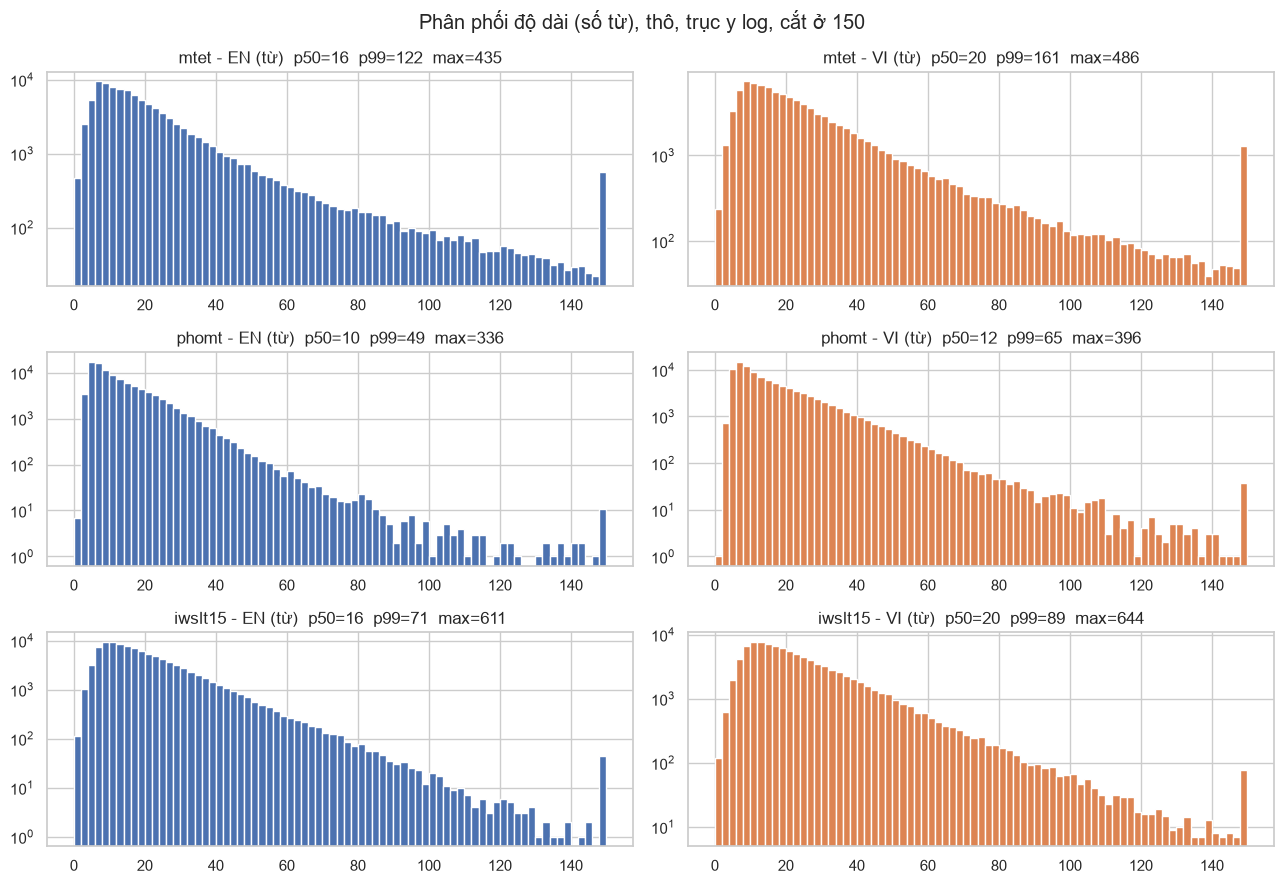

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
bins = np.arange(0, 152, 2)
for i, s in enumerate(['mtet', 'phomt', 'iwslt15']):
    for j, side in enumerate(['en', 'vi']):
        v = eda[s][f'nw_{side}']
        axes[i, j].hist(v.clip(upper=150), bins=bins, color=sns.color_palette()[j])
        axes[i, j].set_title(f'{s} - {side.upper()} (từ)  p50={v.median():.0f}  p99={v.quantile(.99):.0f}  max={v.max()}')
        axes[i, j].set_yscale('log')
fig.suptitle('Phân phối độ dài (số từ), thô, trục y log, cắt ở 150')
fig.tight_layout(); fig.savefig(FIGS / 'eda_len_hist.png', dpi=110); plt.show()

### Phân phối tỉ lệ $r = n_{vi}/n_{en}$ và chọn ngưỡng

Đường nét đứt = $p_1, p_5, p_{50}, p_{95}, p_{99}$ của từng nguồn; vùng tô xanh = khoảng giữ lại $[0.5, 2.5]$ của train. Bảng bên dưới cho biết tỉ lệ dòng nằm trong vùng giữ để xác nhận ngưỡng chỉ cắt phần đuôi.

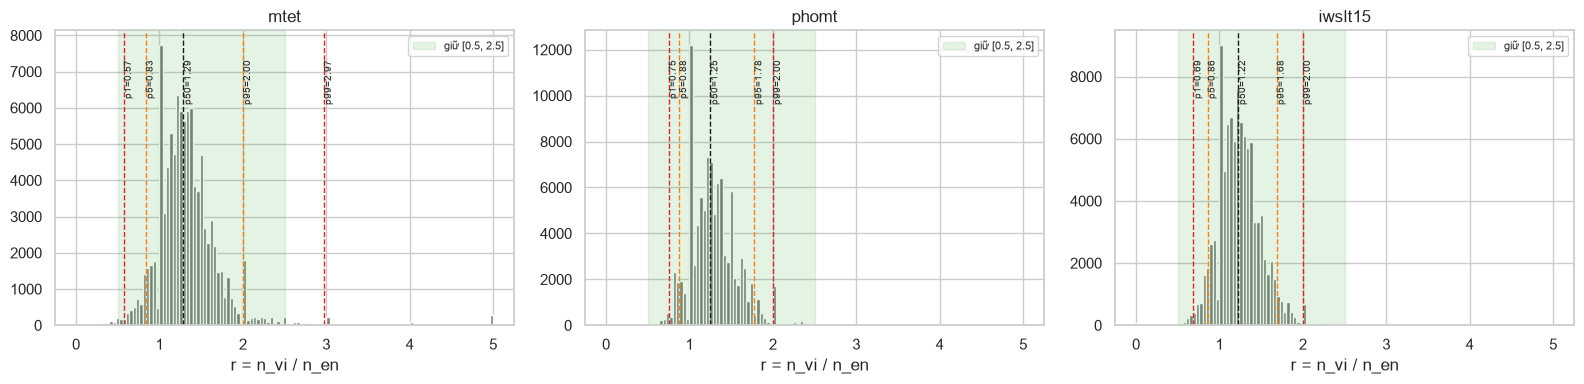

,source,p1,p5,p50,p95,p99,keep_pct_word_ratio,keep_pct_char_ratio
0,mtet,0.571,0.833,1.288,2.000,2.97,97.902,98.395
1,phomt,0.750,0.875,1.250,1.778,2.00,99.913,99.938
2,iwslt15,0.688,0.857,1.222,1.684,2.00,99.724,99.492


In [5]:
LO, HI = TRAIN_BOUNDS['r_lo'], TRAIN_BOUNDS['r_hi']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
rows = []
for ax, s in zip(axes, ['mtet', 'phomt', 'iwslt15']):
    r = eda[s].r
    ax.hist(r.clip(upper=5), bins=np.linspace(0, 5, 126), color='gray')
    ax.axvspan(LO, HI, color='tab:green', alpha=.12, label=f'giữ [{LO}, {HI}]')
    qs = r.quantile([.01, .05, .5, .95, .99])
    for q, col in zip(qs.index, ['tab:red', 'tab:orange', 'k', 'tab:orange', 'tab:red']):
        ax.axvline(qs[q], ls='--', c=col, lw=1)
        ax.text(qs[q], ax.get_ylim()[1] * .9, f'p{int(q*100)}={qs[q]:.2f}', rotation=90, fontsize=7, va='top')
    ax.set_title(s); ax.set_xlabel('r = n_vi / n_en'); ax.legend(loc='upper right', fontsize=8)
    rows.append(dict(source=s, p1=qs[.01], p5=qs[.05], p50=qs[.5], p95=qs[.95], p99=qs[.99],
                     keep_pct_word_ratio=100 * r.between(LO, HI).mean(),
                     keep_pct_char_ratio=100 * (eda[s].nc_vi / eda[s].nc_en.clip(lower=1)).between(TRAIN_BOUNDS['cr_lo'], TRAIN_BOUNDS['cr_hi']).mean()))
fig.tight_layout(); fig.savefig(FIGS / 'eda_ratio.png', dpi=110); plt.show()
display(pd.DataFrame(rows).round(3))

### Tỉ lệ ký tự có dấu tiếng Việt (cơ sở của luật nhận diện ngôn ngữ nhẹ)

Với câu tiếng Việt đúng, hầu như luôn có ít nhất một ký tự trong tập $V$ (`à á ả ... đ`). Ngược lại phía EN gần như không có. Hai thống kê:

$$ d_{en}(s) = \frac{|\{c \in s : c \in V\}|}{|s|}, \qquad \text{vi\_no\_diac}(s) = \big[\,|s|>20 \ \wedge\ \forall c\in s: c\notin V\,\big] $$

Tỉ lệ dòng thoả điều kiện loại ở dữ liệu thô cho thấy mức độ lẫn ngôn ngữ / sai hướng (đặc biệt MTet).

,source,pct_vi_no_diacritic_len_gt20,pct_en_diac_frac_gt_thr,mean_en_diac_frac
0,iwslt15,0.045,0.002,0.0000
1,phomt,0.036,0.015,0.0001
2,mtet,0.279,0.125,0.0004


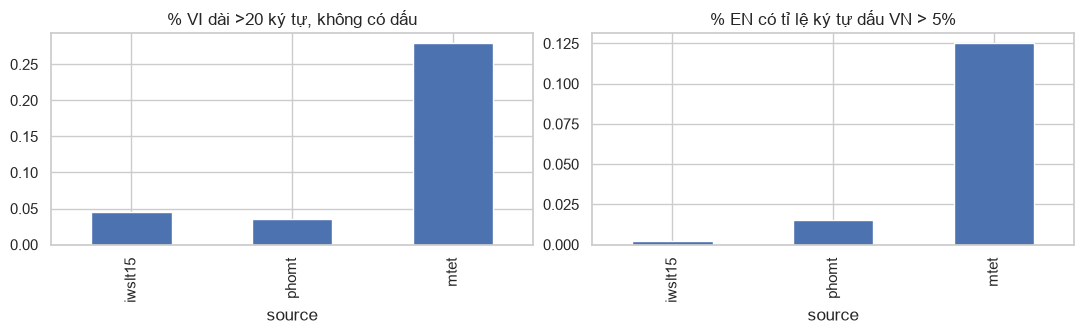

In [6]:
rows = []
for s, d in eda.items():
    rows.append(dict(source=s,
                     pct_vi_no_diacritic_len_gt20=100 * (d.diac_vi0 & (d.nc_vi > VI_NODIAC_MIN_CHARS)).mean(),
                     pct_en_diac_frac_gt_thr=100 * (d.diac_en > EDA_EN_DIAC_FRAC).mean(),
                     mean_en_diac_frac=d.diac_en.mean()))
diac_tbl = pd.DataFrame(rows)
display(diac_tbl.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
diac_tbl.set_index('source')[['pct_vi_no_diacritic_len_gt20']].plot.bar(ax=ax[0], legend=False, title='% VI dài >20 ký tự, không có dấu')
diac_tbl.set_index('source')[['pct_en_diac_frac_gt_thr']].plot.bar(ax=ax[1], legend=False, title='% EN có tỉ lệ ký tự dấu VN > 5%')
fig.tight_layout(); fig.savefig(FIGS / 'eda_diacritic.png', dpi=110); plt.show()

## 3. Detokenizer dùng chung

Cả 3 nguồn đều bị tokenize ở mức khác nhau (khoảng trắng trước dấu câu, `I 'm`, `do n't`, `&apos;`). Nếu để nguyên, mô hình học trên văn bản không tự nhiên, và dedup giữa các nguồn sẽ không bao giờ khớp (cùng một câu nhưng khác khoảng trắng). Vì vậy dùng **một** hàm `detokenize(text, lang)` cho cả ba nguồn:

1. `html.unescape` lặp tới điểm bất động (xử lý cả `&amp;quot;`) $\Rightarrow$ đảm bảo luỹ đẳng.
2. `normalize_text`: NFC, bỏ ký tự vô hình/điều khiển (BOM, zero-width, ...), gộp khoảng trắng.
3. Bỏ khoảng trắng *trước* `, . ; : ? ! % ) ] }` và *sau* `( [ {`.
4. Gộp ` - ` giữa hai chữ số (`1 - 9 - 2019` $\to$ `1-9-2019`).
5. **Gạch nối tách rời giữa chữ** (`well - behaved`, `two - thirds`, `Kobsa - Mark`): đây là tàn dư tokenize của PhoMT, nhưng PhoMT cũng viết dấu gạch ngang *thật* thành ` - ` (`diuretics - they stimulate`), nên hai trường hợp **giống hệt nhau về dạng** và không có luật hình thức nào tách được. Ta dùng bằng chứng thống kê từ chính dữ liệu: với mỗi từ $w$ (chữ thường, số $\to$ `0`),
$$ \rho_L(w)=\frac{\#\{w \text{ đứng ngay trước gạch nối}\}}{\#w},\qquad \rho_R(w)=\frac{\#\{w \text{ đứng ngay sau gạch nối}\}}{\#w} $$
(đếm cả dạng `a-b` lẫn `a - b` trong pool ngẫu nhiên PhoMT + mẫu MTet + IWSLT, từ có $\ge$ `HY_MIN_TOK` lần). Gộp `w1 - w2` $\to$ `w1-w2` nếu (i) cặp $(w_1,w_2)$ xuất hiện $\ge$ `HY_PAIR_MIN` lần, hoặc (ii) $\rho_L(w_1)\ge\tau$ hoặc $\rho_R(w_2)\ge\tau$ (từ "hay đi kèm gạch nối" như `self`, `year`, `based`, `south`; $\tau$ = `HY_RATE`, EN 0.12, VI 0.25); **không bao giờ gộp** khi một bên là từ chức năng (`and`, `they`, `và`, ...) hoặc là số (trừ cặp thường gặp như `10-year`). Câu như `He said - and I agree - that` vì thế được giữ nguyên. Từ điển cố định (seed cố định) nên hàm vẫn tất định và luỹ đẳng.
6. Gộp ` / ` giữa hai ký tự chữ-số (`24 / 7` $\to$ `24/7`, `Photo / Video` $\to$ `Photo/Video`), trừ dòng có phiên âm IPA (`(/ ˈproʊ /`).
7. Co rút `I 'm`, `do n't`, `don 't` (kiểu IWSLT), `'s 're 've 'll 'd` cho **cả hai phía** (phía VI cũng chứa tên/tiêu đề tiếng Anh như `Snake 's End`), kể cả sau dấu đóng ngoặc (`(GDT) 's` $\to$ `(GDT)'s`).
8. Xử lý dấu nháy kép **sau cùng** (để luỹ đẳng): nếu số `"` chẵn thì cắt khoảng trắng *bên trong* cặp (`" abc "` $\to$ `"abc"`); nếu lẻ (câu cụt hoặc trích dẫn bị cắt) thì sửa dấu ở đầu/cuối dòng và thêm hai luật: dấu mở đứng sau `,`/`:` và theo sau là khoảng trắng (`says, " Why` $\to$ `says, "Why`), dấu đóng đứng sau khoảng trắng (không phải sau chữ số, để giữ dấu inch) và trước dấu câu/hết dòng (`design " .` $\to$ `design".`).

Yêu cầu luỹ đẳng: $\text{detok}(\text{detok}(x)) = \text{detok}(x)$, được kiểm tra bằng `assert` trên mẫu.

In [7]:
_INVISIBLE_RX = re.compile('[\x00-\x08\x0e-\x1b\x7f-\x84\x86-\x9f\u200b-\u200f\u202a-\u202e\u2060\u2066-\u2069\ufeff\u00ad]')
_WS_RX = re.compile(r'\s+')
_PUNCT_BEFORE = re.compile(r'\s+([,.;:?!%)\]}])')
_OPEN_AFTER = re.compile(r'([(\[{])\s+')
_DIGIT_HYPHEN = re.compile(r'(?<=\d) - (?=\d)')
_NT = re.compile(r"(\w) (n't)\b", re.I)
_APOS = re.compile(r"([\w)\]]) ('(?:s|re|ve|ll|d|m|t))\b", re.I)   # 't: IWSLT tách "don 't"; cả sau ")" "]"
_Q_START, _Q_END = re.compile(r'^"\s+'), re.compile(r'\s+"$')
_Q_OPEN_ODD = re.compile(r'([,:]) "\s+(?=\S)')                 # says, " Why  -> says, "Why
_Q_CLOSE_ODD = re.compile(r'(?<=[^\s\d]) "(?=[.,;:?!)]|$)')    # design " .  -> design".  (không đụng dấu inch 5")
_SLASH = re.compile(r'(?<=\w) / (?=\w)')
_IPA_RX = re.compile('[ˈˌː]|\\(/ ')             # dòng có phiên âm IPA: không gộp " / "

# Từ chức năng EN + VI: không bao giờ làm thành phần của từ ghép khi đứng cạnh " - "
_STOP = set(('a an the and or of to in on at for by with from is are was were be as it its he she they we you i this that these '
             'those but not no if so than then there their his her our your my me him them us who whom which what when where '
             'while about into over also very just can could will would should may might do does did has have had been being '
             'am all any each both few more most other some such only own same too s t '
             'và của là một các những có cho được trong với không để này đó khi thì mà cũng đã sẽ rất như từ ở tôi bạn anh em '
             'ông bà họ chúng').split())
HY_LEX = {'en': None, 'vi': None}      # được xây ngay bên dưới từ dữ liệu thô

def _nk(w):
    return re.sub(r'\d+', '0', w.lower())

def build_hyphen_lex(texts, lang):
    '''Từ điển gạch nối từ văn bản thô: cặp (w1, w2) thường gặp, tập từ hay đứng trước (left) / sau (right) gạch nối.
    Đếm cả "a-b" lẫn "a - b". Số -> "0", chữ thường.'''
    T, Lc, Rc, pairs = (collections.Counter() for _ in range(4))
    for t in texts:
        if not isinstance(t, str):
            continue
        T.update(_nk(m) for m in re.findall(r'\w+', t))
        if '-' in t:
            for a, b in re.findall(r'(\w+)(?: - |-)(?=(\w+))', t):
                a, b = _nk(a), _nk(b)
                pairs[(a, b)] += 1; Lc[a] += 1; Rc[b] += 1
    ok = lambda w: T[w] >= HY_MIN_TOK and w not in _STOP and w != '0'
    r = HY_RATE[lang]
    return dict(pairs={k for k, v in pairs.items() if v >= HY_PAIR_MIN},
                left={w for w, v in Lc.items() if ok(w) and v / T[w] >= r},
                right={w for w, v in Rc.items() if ok(w) and v / T[w] >= r})

def _hy_join(l, r, lex):
    '''Có nên gộp "l - r" thành "l-r"? Xem quy tắc ở markdown phía trên.'''
    m1, m2 = re.search(r'\w+$', l), re.match(r'\w+', r)
    if not (m1 and m2):
        return False
    a, b = _nk(m1.group()), _nk(m2.group())
    if a in _STOP or b in _STOP:
        return False
    if (a, b) in lex['pairs']:
        return True
    if a == '0' or b == '0':
        return False
    return a in lex['left'] or b in lex['right']

def _join_hyphens(x, lex):
    '''Duyệt token: gộp "w1 - w2" khi _hy_join đúng (chuỗi "43 - year - old" -> "43-year-old").'''
    t, out, i = x.split(' '), [], 0
    while i < len(t):
        if t[i] == '-' and out and i + 1 < len(t) and _hy_join(out[-1], t[i + 1], lex):
            out[-1] += '-' + t[i + 1]; i += 2
        else:
            out.append(t[i]); i += 1
    return ' '.join(out)

def normalize_text(x):
    '''Bước 1a: unescape HTML (tới điểm bất động), NFC, bỏ ký tự vô hình/điều khiển, gộp khoảng trắng, strip.
    Giá trị không phải chuỗi (NaN/None) -> ''.'''
    if not isinstance(x, str):
        return ''
    if '&' in x:
        for _ in range(3):
            y = html.unescape(x)
            if y == x:
                break
            x = y
    x = unicodedata.normalize('NFC', x)
    x = _INVISIBLE_RX.sub('', x)
    return _WS_RX.sub(' ', x).strip()

def _fix_quotes(x):
    '''Sửa khoảng trắng quanh dấu " theo cặp; nếu số dấu lẻ chỉ sửa ở đầu/cuối dòng.'''
    parts = x.split('"')
    if len(parts) % 2 == 1:                       # số dấu " chẵn: phần tử lẻ nằm trong cặp
        for i in range(1, len(parts), 2):
            parts[i] = parts[i].strip()
        return '"'.join(parts)
    x = _Q_END.sub('"', _Q_START.sub('"', x))
    return _Q_CLOSE_ODD.sub('"', _Q_OPEN_ODD.sub(r'\1 "', x))

def detokenize(x, lang):
    '''Detokenize một câu (lang in {'en','vi'}). Gồm cả normalize_text. Luỹ đẳng.
    Dấu câu, gạch nối (theo HY_LEX[lang]), " / ", dấu nháy kép áp cho cả hai ngôn ngữ; co rút (n't, 's, ...) áp cho cả hai ngôn ngữ.
    Dấu nháy xử lý sau cùng để các luật khác không tạo ra khoảng trắng mới cạnh dấu nháy.'''
    x = normalize_text(x)
    x = _PUNCT_BEFORE.sub(r'\1', x)
    x = _OPEN_AFTER.sub(r'\1', x)
    x = _DIGIT_HYPHEN.sub('-', x)
    if ' - ' in x and HY_LEX[lang] is not None:
        x = _join_hyphens(x, HY_LEX[lang])
    if ' / ' in x and not _IPA_RX.search(x):
        x = _SLASH.sub('/', x)
    if "'" in x:
        x = _NT.sub(r'\1\2', x)
        x = _APOS.sub(r'\1\2', x)
    if '"' in x:
        x = _fix_quotes(x)
    return x

# Từ điển gạch nối: từ pool PhoMT ngẫu nhiên + mẫu MTet + IWSLT (thô, chưa làm sạch)
t0 = time.time()
for _lang in ('en', 'vi'):
    HY_LEX[_lang] = build_hyphen_lex(pd.concat([PHOMT_POOL[_lang], raw_sample['mtet'][_lang], raw_sample['iwslt15'][_lang]]), _lang)
    print(f'HY_LEX[{_lang}]: {len(HY_LEX[_lang]["pairs"]):,} cặp, {len(HY_LEX[_lang]["left"]):,} từ trái, {len(HY_LEX[_lang]["right"]):,} từ phải')
print(f'xây từ điển gạch nối: {time.time() - t0:.0f}s')

assert detokenize('I &apos;m   here , do n&apos;t go ! " Hello " ( ok ) 5 % 1 - 9 - 2019', 'en') == 'I\'m here, don\'t go! "Hello" (ok) 5% 1-9-2019'
assert detokenize('Rachel Pike : a - b', 'vi') == 'Rachel Pike: a - b'
assert detokenize('A fact , 24 / 7 and Photo / Video', 'en') == 'A fact, 24/7 and Photo/Video'
if not SAMPLE:   # từ điển SAMPLE (25k dòng) quá nhỏ để chắc chắn có cặp này
    assert detokenize('A well - known fact', 'en') == 'A well-known fact'
assert detokenize('He said - and I agree - that it works', 'en') == 'He said - and I agree - that it works'
assert detokenize('He says , " Why do n\'t you', 'en') == 'He says, "Why don\'t you'
assert detokenize('Anh nói , " Sao vậy', 'vi') == 'Anh nói, "Sao vậy'
assert detokenize('a 5 " pipe and 3.5 / 2 , 1,000', 'en') == 'a 5 " pipe and 3.5/2, 1,000'
assert detokenize("the (GDT) 's list, Snake 's End and Don 't", 'en') == "the (GDT)'s list, Snake's End and Don't"
assert detokenize("Snake 's End", 'vi') == "Snake's End"
print('unit-test nhỏ OK')

HY_LEX[en]: 4,786 cặp, 437 từ trái, 670 từ phải
HY_LEX[vi]: 1,480 cặp, 132 từ trái, 135 từ phải
xây từ điển gạch nối: 22s
unit-test nhỏ OK


### Ví dụ trước/sau và độ tin cậy của detokenizer

Với mỗi nguồn: (a) vài ví dụ dòng bị thay đổi, (b) tỉ lệ dòng thay đổi bởi `normalize_text` một mình so với toàn bộ `detokenize`, (c) tỉ lệ dòng còn "dấu hiệu tokenize" (khoảng trắng trước dấu câu, `n't` rời) *trước* và *sau* — nếu sau gần 0 nghĩa là luật hiệu quả, (d) kiểm tra luỹ đẳng trên mẫu.

In [8]:
ARTEFACT_OLD_RX = re.compile(r"\s[,.;:?!%)]|[(\[{]\s|\s'(?:s|re|ve|ll|d|m)\b|\sn't\b|\w\s't\b|&(?:apos|quot|amp|#\d+);")
# mở rộng: gạch nối tách rời giữa hai chữ cái, " / " giữa hai ký tự chữ-số, dấu nháy kép mở/đóng còn khoảng trắng thừa
HYPHEN_RX = re.compile(r'[^\W\d_] - [^\W\d_]')
ARTEFACT_RX = re.compile(ARTEFACT_OLD_RX.pattern + r'|\w / \w|[,:] " |\s"(?:[.,;:?!)]|$)')
_s = lambda x: x if isinstance(x, str) else ''
rows, ex_tables, ex_invis = [], {}, {}
for s, df in raw_sample.items():
    for side in ('en', 'vi'):
        before = df[side].tolist()
        after = [detokenize(x, side) for x in before]
        norm = [normalize_text(x) for x in before]
        # luỹ đẳng
        again = [detokenize(x, side) for x in after]
        assert again == after, f'{s}/{side}: detokenize không luỹ đẳng, ví dụ: {[(a, b) for a, b in zip(after, again) if a != b][:2]}'
        rows.append(dict(source=s, side=side,
                         pct_changed_normalize_only=100 * np.mean([a != b for a, b in zip(before, norm)]),
                         pct_changed_full=100 * np.mean([a != b for a, b in zip(before, after)]),
                         pct_artefact_old_rx_before=100 * np.mean([ARTEFACT_OLD_RX.search(_s(x)) is not None for x in before]),
                         pct_artefact_before=100 * np.mean([ARTEFACT_RX.search(_s(x)) is not None for x in before]),
                         pct_artefact_after=100 * np.mean([ARTEFACT_RX.search(x) is not None for x in after]),
                         pct_spaced_hyphen_before=100 * np.mean([HYPHEN_RX.search(_s(x)) is not None for x in before]),
                         pct_spaced_hyphen_after=100 * np.mean([HYPHEN_RX.search(x) is not None for x in after])))
        ex = pd.DataFrame({'before': before, 'after': after})
        stripped = ex.before.map(lambda x: _INVISIBLE_RX.sub('', _s(x)))
        # chỉ giữ dòng thật sự đổi sau khi bỏ ký tự vô hình; dòng chỉ khác do ký tự vô hình hiển thị riêng bằng repr
        ex_tables[(s, side)] = ex[stripped != ex.after].head(5)
        inv = ex[ex.before.map(lambda x: _INVISIBLE_RX.search(_s(x)) is not None)].head(3)
        ex_invis[(s, side)] = inv.assign(before=inv.before.map(repr), after=inv.after.map(repr))
print('Luỹ đẳng: OK trên toàn bộ mẫu EDA của cả 3 nguồn, 2 phía')
detok_stats = pd.DataFrame(rows)
display(detok_stats.round(2))
print('pct_artefact_* dùng ARTEFACT_RX (dấu câu/co rút/entity + " / " + nháy kép + gạch nối giữa chữ cái, vì vậy phần gạch nối GIỮ LẠI '
      'là dấu gạch ngang thật hoặc từ ghép chưa nhận ra); pct_spaced_hyphen_* chỉ tính riêng gạch nối.')
for (s, side), ex in ex_tables.items():
    print(f'\n--- {s} / {side.upper()} (chỉ dòng đổi thật sự) ---')
    display(ex)
    iv = ex_invis[(s, side)]
    if len(iv):
        print(f'--- {s} / {side.upper()}: dòng có ký tự vô hình (repr) ---')
        display(iv)

Luỹ đẳng: OK trên toàn bộ mẫu EDA của cả 3 nguồn, 2 phía


,source,side,pct_changed_normalize_only,pct_changed_full,pct_artefact_old_rx_before,pct_artefact_before,pct_artefact_after,pct_spaced_hyphen_before,pct_spaced_hyphen_after
0,iwslt15,en,40.19,99.81,99.81,99.81,0.00,0.00,0.00
1,iwslt15,vi,8.14,94.68,94.67,94.68,0.01,0.92,0.89
2,phomt,en,0.01,12.56,7.99,8.68,0.03,5.90,2.65
3,phomt,vi,0.15,1.72,0.36,1.14,0.02,1.06,0.82
4,mtet,en,0.31,17.00,7.29,13.58,0.03,0.02,0.02
5,mtet,vi,1.29,17.30,7.10,13.00,0.04,0.00,0.00


pct_artefact_* dùng ARTEFACT_RX (dấu câu/co rút/entity + " / " + nháy kép + gạch nối giữa chữ cái, vì vậy phần gạch nối GIỮ LẠI là dấu gạch ngang thật hoặc từ ghép chưa nhận ra); pct_spaced_hyphen_* chỉ tính riêng gạch nối.

--- iwslt15 / EN (chỉ dòng đổi thật sự) ---


,before,after
0,"So as we are facing all the multiple crises in our world at the moment , what is good for us on a personal level , what &apos;s going to bring more joy , gr...","So as we are facing all the multiple crises in our world at the moment, what is good for us on a personal level, what's going to bring more joy, gratitude, ..."
1,You see that really salty Play-Doh ?,You see that really salty Play-Doh?
2,"The vast majority of interactions I see -- and I see a lot , believe me -- are positive , people reaching out to help or to connect or share information wit...","The vast majority of interactions I see -- and I see a lot, believe me -- are positive, people reaching out to help or to connect or share information with ..."
3,"And there is a story -- it &apos;s a real story -- about my grandmother buying a carp on Thursday , bringing it home , putting it in the bathtub when I was ...","And there is a story -- it's a real story -- about my grandmother buying a carp on Thursday, bringing it home, putting it in the bathtub when I was a kid."
4,"It took me several months to design the column , but ultimately it takes the computer about 30 seconds to calculate all of the 16 million faces .","It took me several months to design the column, but ultimately it takes the computer about 30 seconds to calculate all of the 16 million faces."


--- iwslt15 / EN: dòng có ký tự vô hình (repr) ---


,before,after
94376,"'My favorite and most successful app is Bustin Jieber , which is â \x80 \x94 â \x80 \x94 which is a Justin Bieber Whac-A-Mole .'","'My favorite and most successful app is Bustin Jieber, which is â â which is a Justin Bieber Whac-A-Mole.'"


... (14 outputs left out)


--- mtet / VI (chỉ dòng đổi thật sự) ---


,before,after
7,"Tiền sản giật, tăng huyết áp thai kỳ, PAPP-A, βhCG, sàng lọc trước sinh.","Tiền sản giật, tăng huyết áp thai kỳ, PAPP-A, βhCG, sàng lọc trước sinh."
15,""" Nói với em rằng anh sẽ không đi đâu cả. Rằng Clare không muốn có Gomez. Rằng mọi chuyện sẽ ổn thoả. Hoặc nói rằng tất cả chỉ là tưởng tượng. Hãy nói với e...","""Nói với em rằng anh sẽ không đi đâu cả. Rằng Clare không muốn có Gomez. Rằng mọi chuyện sẽ ổn thoả. Hoặc nói rằng tất cả chỉ là tưởng tượng. Hãy nói với em..."
34,""" Cô có thể động đậy tay phải một chút cho tôi xem không? "" tôi hỏi Shizuko. Và cô nhấc các ngón của bàn tay phải lên. Tôi chắc là cô phải cố, các ngón tay ...","""Cô có thể động đậy tay phải một chút cho tôi xem không?"" tôi hỏi Shizuko. Và cô nhấc các ngón của bàn tay phải lên. Tôi chắc là cô phải cố, các ngón tay cử..."
38,"Ông báo cho cả lớp rằng tất cả đều đã sai. đoạn mở đầu cho câu chuyện, theo như lời ông nói, là: "" học sinh sẽ không phải đến trường vào ngày thứ năm. ""","Ông báo cho cả lớp rằng tất cả đều đã sai. đoạn mở đầu cho câu chuyện, theo như lời ông nói, là: ""học sinh sẽ không phải đến trường vào ngày thứ năm."""
41,"Tương tự, một số tường thuật về sự kiện nói rằng: "" Đài phát thanh Veritas trên thực tế là dây rốn của chúng tôi để cho bất kỳ điều gì khác diễn ra. ""","Tương tự, một số tường thuật về sự kiện nói rằng: ""Đài phát thanh Veritas trên thực tế là dây rốn của chúng tôi để cho bất kỳ điều gì khác diễn ra."""


--- mtet / VI: dòng có ký tự vô hình (repr) ---


,before,after
58,"'Trong cả hai thời tiết rất nóng và rất lạnh, chúng có thể ở trong hang bị bỏ rơi của cáo, chó rừng, hoặc thú ăn kiến\u200b.'","'Trong cả hai thời tiết rất nóng và rất lạnh, chúng có thể ở trong hang bị bỏ rơi của cáo, chó rừng, hoặc thú ăn kiến.'"
793,'- Về số lư\xadợng: Giáo viên dạy lý thuyết tối đa 1 giáo viên/35 học sinh; dạy thực hành tối đa 1 giáo viên/18 học sinh;','- Về số lượng: Giáo viên dạy lý thuyết tối đa 1 giáo viên/35 học sinh; dạy thực hành tối đa 1 giáo viên/18 học sinh;'
3373,'Địa điểm này đã không được phát hiện cho đến năm 1851 khi các tàu tì kiếm của Anh và Mỹ \u200b\u200bneo đậu gần đó.','Địa điểm này đã không được phát hiện cho đến năm 1851 khi các tàu tì kiếm của Anh và Mỹ neo đậu gần đó.'


### 40 cặp trước/sau cho gạch nối, " / " và dấu nháy (kèm ca biên)

Lấy từ pool ngẫu nhiên của PhoMT (seed cố định), chỉ in "cửa sổ" quanh dấu gạch nối / dấu nháy để dễ soi. 30 cặp đầu là dòng **bị đổi**, 10 cặp sau là dòng có ` - ` giữa chữ cái nhưng **được giữ nguyên** (ca biên: dấu gạch ngang thật, tên riêng, từ ghép chưa có trong từ điển). Dùng để ước lượng độ chính xác của luật gạch nối bằng mắt.

In [9]:
def _win(x, rx):
    return ' | '.join(m.group() for m in rx.finditer(x))[:140]
_rng = np.random.default_rng(SEED)
pool_en = PHOMT_POOL['en'].dropna()
cand = pool_en[pool_en.str.contains(r'\w - \w|\w / \w|, " |\s"[.,;:?!)]')]
cand = cand.sample(min(3000, len(cand)), random_state=SEED).tolist()
changed_, kept_ = [], []
for x in cand:
    y = detokenize(x, 'en')
    (changed_ if _INVISIBLE_RX.sub('', x) != y else kept_).append((x, y))
WIN = re.compile(r'\S+(?: [-/])+ \S+|\S* " \S*|\S*\s"[.,;:?!)]')
WIN2 = re.compile(r'\S*\w[-/]\S+|\S+[-/]\w\S*|\S*"\S*')
for k, (x, y) in enumerate(changed_[:30] + kept_[:10]):
    tag = 'ĐỔI ' if k < 30 else 'GIỮ '
    print(f'{tag}| {_win(x, WIN):<60} -> {_win(y, WIN2)}' if k < 30 else f'{tag}| {_win(x, WIN)}')
print(f'\nTrong 3000 dòng ứng viên: đổi {len(changed_)}, giữ {len(kept_)}')

print('\n--- Dấu nháy kép (IWSLT/MTet), ví dụ trước -> sau ---')
for s in ('iwslt15', 'mtet'):
    for side in ('en', 'vi'):
        q = raw_sample[s][side].dropna()
        q = q[q.str.contains(r'[,:] " \S') & (q.str.count('"') % 2 == 1)].head(3)
        for x in q:
            print(f'{s}/{side}: {x[:110]!r}\n{"":11s}-> {detokenize(x, side)[:110]!r}')

ĐỔI | five - year | 1 - 2                                          -> five-year | 1-2
ĐỔI | medium - class                                               -> medium-class
ĐỔI | 20th - century                                               -> 20th-century
ĐỔI | night - time,                                                -> night-time,
ĐỔI | Party - affiliated                                           -> Party-affiliated
ĐỔI | Woo - ping                                                   -> Woo-ping
ĐỔI | 1939 - 1945,                                                 -> 1939-1945,
ĐỔI | water - cooled                                               -> water-cooled
ĐỔI | African - Americans                                          -> African-Americans
ĐỔI | Environment - current | water - borne                        -> water-borne
ĐỔI | standard - sized                                             -> 1/4 | standard-sized
ĐỔI | WASP - 17b | Kepler - 7b's                                   -> WASP-

## 4. Các luật làm sạch

Mỗi luật là một hàm `rule_*(df, P, source)` trả về **mask giữ lại** (`True` = giữ). Các luật được áp tuần tự trên các dòng còn sống, nên mỗi dòng bị tính cho **luật đầu tiên** loại nó. `RuleLog` ghi số dòng bị loại theo (nguồn, split, luật) và vài ví dụ bị loại. Cột *phạm vi*: `all` = áp cho cả train/valid/test; `train` = chỉ loại ở train, ở valid/test chỉ **đếm** (không làm méo tập đánh giá).

| # | Luật | Phạm vi | Ý nghĩa |
|---|---|---|---|
| 0 | `r01_mojibake` | all | **trước** detokenize: sửa lỗi mã hoá (`â€œ`, `Â°`) nếu mã hoá lại cp1252/latin-1 rồi giải mã UTF-8 thành công; không sửa được hoặc có `U+FFFD` thì loại dòng (mục bên dưới) |
| 1 | detokenize + NFC + bỏ ký tự vô hình + gộp trắng | all | biến đổi (không loại), đo số dòng thay đổi |
| 2 | `r02_empty` | all | rỗng/null ở một phía |
| 11 | `r11_no_content` | all | một phía có $<2$ chữ cái hoặc chỉ là số thứ tự/gạch đầu dòng (`2.`, `(a)`) |
| 3 | `r03_identical` | all | EN == VI (không phân biệt hoa thường): thường là chưa dịch |
| 4 | `r04_html` | all | còn thẻ HTML `<[^>]+>` |
| 5 | `r05_url` | all | URL chiếm $\ge$ `URL_FRAC` ký tự của câu |
| 6 | `r06_word_bounds` | all | số từ $\in[\text{min},\text{max}]$ và số ký tự $\le$ max (MTet min 2 từ vì có nhiều mảnh 1 từ) |
| 7 | `r07_len_ratio` | all | $r\in[0.5,2.5]$ theo từ, và tỉ lệ ký tự trong $[c_{lo},c_{hi}]$ (kiểm tra thêm) |
| 8 | `r08_lang_id` | all | VI dài $>20$ ký tự, không dấu nào **và có $\ge5$ chữ cái ASCII**; hoặc EN có $\ge3$ ký tự dấu VN **trong từ viết thường** với tỉ lệ $>0.01$ |
| 12 | `r12_near_copy` | all | EN $\approx$ VI (câu $>20$ ký tự): giống hệt sau khi bỏ số/dấu câu, hoặc difflib ratio $>0.8$ |
| 13 | `r13_vi_english` | all | VI không dấu nào mà có $\ge3$ từ chức năng tiếng Anh (`the and of is`...) |
| 14 | `r14_num_misaligned` | train | cả hai phía có số mà hai tập số rời nhau hoàn toàn |
| 15 | `r15_odd_quotes` | train | số dấu `"` lẻ ở một phía (không tính dấu inch `5"`) |
| 16 | `r16_artefact` | train | còn tàn dư tokenize ` 's`/` n't`/`w / w` mà detokenizer không sửa được |
| 9 | `r09_dup_pair` | train | trùng cặp (toàn cục, ưu tiên PhoMT > IWSLT > MTet) — bước tổng hợp |
| 10 | `r10_eval_overlap` | train | cặp, câu EN **hoặc câu VI** (khoá chuẩn hoá) của train trùng valid/test — bước tổng hợp |
| 9b | `r09b_dup_en` | train | trùng khoá EN với một dòng đã giữ (cùng câu nguồn, khác bản dịch) |
| 9c | `r09c_dup_vi` | train | trùng khoá VI với một dòng đã giữ |
| 10b | `r10_valid_overlap` | test | cặp, câu EN hoặc câu VI của **test** trùng valid — loại khỏi test |


### Luật r01: mojibake (sửa nếu chắc chắn, nếu không thì loại)

**Vì sao.** Một phần MTet/PhoMT bị đọc nhầm UTF-8 như cp1252/latin-1 (`“I'm` $\to$ `â€œI'm`; `½` $\to$ `Â½`; `é` $\to$ `Ã©`) hoặc đã mất hẳn thông tin (`U+FFFD`: `Bogot��`). Tokenizer sẽ học các chuỗi rác này như từ thật. Phải xử lý **trước** detokenize vì `normalize_text` xoá ký tự điều khiển C1 (`\x80-\x9f`), vốn là bằng chứng của lỗi.

**Sửa.** Với chuỗi $s$ có dấu hiệu lỗi (tập $M$ = `MOJI_RX`: `U+FFFD`, `Ã|Â` + byte tiếp nối, `â€`, chữ cái dẫn UTF-8 + ký hiệu Latin-1, ký tự C1 trơ trọi):
$$ \hat s=\mathrm{decode}_{\text{utf-8}}^{\text{strict}}\big(\mathrm{bytes}_{\text{cp1252/latin-1}}(s)\big),\qquad \text{chấp nhận khi } |M(\hat s)|<|M(s)| \ \wedge\ M(\hat s)=\emptyset $$
nếu cả dòng không mã hoá lại được (dòng lẫn chữ Việt đúng chuẩn như `ễ`, không có trong cp1252) thì chỉ sửa **từng đoạn** mojibake. Mẫu `â€ "` (dấu gạch ngang `—` bị tokenize) được khôi phục riêng. Mọi ca khác bị **loại** (dòng chứa `U+FFFD` luôn bị loại vì thông tin đã mất).

**Dương tính giả.** Chữ Việt hợp lệ có thể trùng byte dẫn UTF-8 (`Ã`, `Â`, `à`, `ô`...): vì vậy `à…` / `mà…` không bị gắn cờ (byte dẫn là chữ Việt chỉ tính khi theo sau là ký hiệu Latin-1 `¡-¿`), và `â` chỉ tính khi theo sau là `€ ‚ „ † ‡ ˆ ‰`. Độ chính xác được kiểm tra bằng mẫu VI ở phần minh hoạ.


In [10]:
_C1_CP1252 = ''.join(bytes([b]).decode('cp1252') for b in range(0x80, 0xa0) if b not in (0x81, 0x8d, 0x8f, 0x90, 0x9d))
_VI_LEAD = 'àáãèéêìíòóôõùúýÀÁÈÉÊÌÍÒÓÔÕÙÚÝ'            # chữ cái tiếng Việt hợp lệ nằm trong khoảng byte dẫn UTF-8 (0xC2-0xF4)
_OTHER_LEAD = ''.join(c for c in map(chr, range(0xc4, 0xf5)) if c not in _VI_LEAD + 'â')   # Ä Å Æ Ð Ñ ï ...: không phải chữ Việt
_CONT = '\x80-\xac\xae-\xbf' + re.escape(_C1_CP1252)  # byte tiếp nối UTF-8 bị đọc nhầm thành latin-1 / cp1252 (bỏ \xad)
# Chữ Việt hợp lệ + dấu câu (mà… / bây…) KHÔNG được bắt nhầm: các byte dẫn là chữ Việt (à é ô...) chỉ tính khi theo sau là ký hiệu Latin-1 (¡-¿)
# và 'â' chỉ tính khi theo sau là € ‚ „ † ‡ ˆ ‰ (mẫu "â€œ"), còn Ã/Â (không bao giờ đứng trước ký hiệu Latin-1 trong tiếng Việt thật) tính với mọi byte tiếp nối.
MOJI_RX = re.compile('�|[\x80-\x9f]|[ÃÂ][\x80-\xbf]|â[€‚„†‡ˆ‰]|['
                     + _VI_LEAD + '][\xa1-\xac\xae-\xbf]|[' + _OTHER_LEAD + '][' + _CONT + ']')
_MOJI_RUN = re.compile('(?:[Â-ô][' + _CONT + '\xa0]{1,3})+')
_EMDASH_TOK = 'â€ "'        # "—" (E2 80 94) bị đọc nhầm rồi bị tokenize: 0x94 -> " tách rời

def _to_bytes(s):
    '''Chuỗi bị đọc nhầm (latin-1 hoặc cp1252, hoặc lẫn cả hai) -> bytes gốc. Ném UnicodeEncodeError nếu có ký tự ngoài cả hai bảng mã.'''
    b = bytearray()
    for c in s:
        o = ord(c)
        b += bytes([o]) if o < 256 else c.encode('cp1252')
    return bytes(b)

def _recode(s):
    '''Thử sửa mojibake: bytes(s) giải mã lại bằng UTF-8 (strict). Trả về None nếu không được.'''
    try:
        return _to_bytes(s).decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return None

def repair_mojibake(s):
    '''Trả về (chuỗi mới, trạng thái): None = không có dấu hiệu lỗi; 'fixed' = đã sửa (số dấu hiệu lỗi giảm NGHIÊM NGẶT và
    không còn dấu hiệu nào); 'drop' = không sửa được hoặc có U+FFFD (mất thông tin, không thể phục hồi).
    Thử cả dòng trước; nếu thất bại (dòng lẫn chữ Việt đúng chuẩn nên không mã hoá lại được) thì sửa từng đoạn mojibake.'''
    n0 = len(MOJI_RX.findall(s))
    if n0 == 0:
        return s, None
    if '�' in s:
        return s, 'drop'
    u = s.replace(_EMDASH_TOK, 'â€”')
    t = _recode(u)
    if t is None:
        t = _MOJI_RUN.sub(lambda m: _recode(m.group()) or m.group(), u)
    t = unicodedata.normalize('NFC', t)
    if len(MOJI_RX.findall(t)) < n0 and not MOJI_RX.search(t):
        return t, 'fixed'
    return s, 'drop'

# unit-test: ca sửa được, ca phải loại, và ca chữ Việt hợp lệ KHÔNG được gắn cờ
assert repair_mojibake("â€œI'm sad") == ("“I'm sad", 'fixed')
assert repair_mojibake('Serve with Â½ cup at 70 Â°F') == ('Serve with ½ cup at 70 °F', 'fixed')
assert repair_mojibake('Nguyễn nói â€œchào bạnâ€\x9d') == ('Nguyễn nói “chào bạn”', 'fixed')   # lẫn chữ Việt chuẩn: sửa từng đoạn
assert repair_mojibake('Cuối tuần â€ " vui') == ('Cuối tuần — vui', 'fixed')
assert repair_mojibake('y\ufffd\ufffdur')[1] == 'drop' and repair_mojibake('owen\x92s')[1] == 'drop'
assert repair_mojibake('Tôi nói mà… NHÃ ÂM, bây giờ')[1] is None and repair_mojibake('café\xa0: ok')[1] is None
print('unit-test mojibake OK')


unit-test mojibake OK


In [11]:
class RuleLog:
    '''Ghi số dòng bị loại theo (nguồn, split, luật), số dòng vào, số dòng đổi bởi luật 1, số dòng được sửa mojibake,
    số dòng bị GẮN CỜ nhưng giữ lại (luật chỉ áp cho train, đo ở valid/test) và <=3 ví dụ bị loại mỗi (nguồn, luật).'''
    def __init__(self):
        self.drops = collections.Counter()
        self.n_in = collections.Counter()
        self.changed = collections.Counter()
        self.repaired = collections.Counter()          # (nguồn, split, phía) -> số câu mojibake được sửa
        self.repair_ex = []                            # (nguồn, split, phía, trước, sau)
        self.flagged = collections.Counter()           # (nguồn, split, luật) -> số dòng vi phạm nhưng được giữ (valid/test)
        self.examples = collections.defaultdict(list)

    def add(self, source, split, rule, n):
        self.drops[(source, split, rule)] += int(n)

    def add_examples(self, source, split, rule, pairs, k=3):
        ex = self.examples[(source, split, rule)]
        for en, vi in pairs:
            if len(ex) < k:
                ex.append((en, vi))

    def table(self):
        return pd.DataFrame([dict(source=s, split=sp, rule=r, dropped=n) for (s, sp, r), n in sorted(self.drops.items())])

    def examples_table(self, split='train'):
        rows = [dict(rule=r, source=s, en=en[:200], vi=vi[:200]) for (s, sp, r), v in sorted(self.examples.items(), key=lambda kv: (kv[0][2], kv[0][0])) if sp == split for en, vi in v]
        return pd.DataFrame(rows)

def add_features(df):
    '''Tính độ dài ký tự (nc_*) và số từ (nw_*) trên văn bản đã chuẩn hoá (khoảng trắng đơn).'''
    for side in ('en', 'vi'):
        df[f'nc_{side}'] = df[side].str.len()
        df[f'nw_{side}'] = np.where(df[f'nc_{side}'] > 0, df[side].str.count(' ') + 1, 0)
    return df

def rule_empty(df, P, source):
    '''Luật 2: giữ dòng mà cả hai phía đều không rỗng.'''
    return ((df.nc_en > 0) & (df.nc_vi > 0)).to_numpy()

_LET2 = re.compile(r'[^\W\d_][\W\d_]*[^\W\d_]')                     # có ít nhất 2 chữ cái (không nhất thiết liền nhau)
_NUMBERING = re.compile(r'[(\[]?(?:[0-9]{1,3}|[A-Za-z]|[ivxIVX]{1,4})[.)\]]+')   # "2." "(a)" "iv)" : chỉ là đánh số
def _no_content(x):
    return _LET2.search(x) is None or _NUMBERING.fullmatch(x) is not None

def rule_no_content(df, P, source):
    '''Luật 11: loại dòng mà một phía có < 2 chữ cái hoặc chỉ là số thứ tự/gạch đầu dòng ("2.", "(a)").'''
    return np.array([not (_no_content(a) or _no_content(b)) for a, b in zip(df.en, df.vi)], dtype=bool)

def rule_identical(df, P, source):
    '''Luật 3: loại dòng EN == VI (casefold): thường là chưa dịch/sao chép.'''
    return (df.en.str.casefold() != df.vi.str.casefold()).to_numpy()

HTML_RX = re.compile(r'<[^>]+>')
def rule_html(df, P, source):
    '''Luật 4: loại dòng còn thẻ HTML ở bất kỳ phía nào.'''
    return ~(df.en.str.contains(HTML_RX) | df.vi.str.contains(HTML_RX)).to_numpy()

URL_RX = re.compile(r'(?:https?://|ftp://|www\.)\S+', re.I)
def _url_frac(texts):
    return np.array([sum(map(len, URL_RX.findall(x))) / max(len(x), 1) for x in texts])

def rule_url(df, P, source):
    '''Luật 5: loại dòng có URL chiếm >= URL_FRAC số ký tự (URL-only / URL-heavy).'''
    return ~((_url_frac(df.en) >= URL_FRAC) | (_url_frac(df.vi) >= URL_FRAC))

def rule_word_bounds(df, P, source):
    '''Luật 6: số từ trong [min_words[source], max_words] và số ký tự <= max_chars ở cả hai phía.'''
    mn = P['min_words'][source]
    return ((df.nw_en >= mn) & (df.nw_vi >= mn) & (df.nw_en <= P['max_words']) & (df.nw_vi <= P['max_words'])
            & (df.nc_en <= P['max_chars']) & (df.nc_vi <= P['max_chars'])).to_numpy()

def rule_len_ratio(df, P, source):
    '''Luật 7: r = n_vi/n_en trong [r_lo, r_hi] và tỉ lệ ký tự trong [cr_lo, cr_hi].'''
    r = df.nw_vi / df.nw_en.clip(lower=1)
    cr = df.nc_vi / df.nc_en.clip(lower=1)
    return (r.between(P['r_lo'], P['r_hi']) & cr.between(P['cr_lo'], P['cr_hi'])).to_numpy()

def _diac_count(texts):
    return np.array([len(VI_RX.findall(x)) for x in texts])

_ASCII_L = re.compile('[A-Za-z]')
def en_diac_lower(x):
    '''Số ký tự dấu tiếng Việt nằm trong các từ BẮT ĐẦU bằng chữ thường (từ thường của tiếng Việt, khác tên riêng viết hoa).'''
    return sum(len(VI_RX.findall(w)) for w in re.findall(r'\w+', x) if w[0].islower())

def rule_lang_id(df, P, source):
    '''Luật 8 (nhận diện ngôn ngữ nhẹ): loại
    (a) VI dài > VI_NODIAC_MIN_CHARS mà không có ký tự dấu VN và có >= VI_NODIAC_MIN_LETTERS chữ cái ASCII
        (câu toàn số/dấu như "10, 9, 8, 7, 6..." là VI hợp lệ không dấu);
    (b) EN có >= EN_DIAC_MIN_COUNT ký tự dấu VN nằm trong các từ viết thường (xem en_diac_lower) VÀ tỉ lệ ký tự dấu đó
        > EN_DIAC_MAX_FRAC: câu EN thực chất chứa tiếng Việt/chưa dịch. Chỉ đếm từ viết thường vì tên riêng
        ("Nguyễn Thị Thủy", "Hà Nội", "Café Société": từ viết hoa) là tiếng Anh hợp lệ, không được loại.'''
    n_letters = np.array([len(_ASCII_L.findall(x)) for x in df.vi])
    vi_bad = (df.nc_vi.to_numpy() > VI_NODIAC_MIN_CHARS) & (_diac_count(df.vi) == 0) & (n_letters >= VI_NODIAC_MIN_LETTERS)
    en_bad = np.zeros(len(df), bool)
    nc = df.nc_en.to_numpy()
    for i in np.flatnonzero(_diac_count(df.en) >= EN_DIAC_MIN_COUNT):    # cổng rẻ: chỉ tính kỹ các dòng có đủ ký tự dấu
        n = en_diac_lower(df.en.iat[i])
        en_bad[i] = n >= EN_DIAC_MIN_COUNT and n / max(nc[i], 1) > EN_DIAC_MAX_FRAC
    return ~(vi_bad | en_bad)

_NONLET = re.compile(r'[\W\d_]+')
_WORD = re.compile(r'\w+')
def is_near_copy(en, vi):
    '''EN và VI (câu > NEAR_COPY_MIN_CHARS ký tự) gần như là một: (i) giống hệt sau khi bỏ số/dấu câu/khoảng trắng, hoặc
    (ii) tập từ chung >= 50% (cổng rẻ tiền) và difflib ratio trên chuỗi casefold > NEAR_COPY_RATIO.'''
    if len(en) <= NEAR_COPY_MIN_CHARS:
        return False
    a, b = en.casefold(), vi.casefold()
    if _NONLET.sub('', a) == _NONLET.sub('', b):
        return True
    wa, wb = set(_WORD.findall(a)), set(_WORD.findall(b))
    if 2 * len(wa & wb) < len(wa | wb):
        return False
    return difflib.SequenceMatcher(None, a, b, autojunk=False).ratio() > NEAR_COPY_RATIO

def rule_near_copy(df, P, source):
    '''Luật 12: loại dòng mà EN ≈ VI (xem is_near_copy): bản dịch chỉ là sao chép nguồn.'''
    return np.array([not is_near_copy(a, b) for a, b in zip(df.en, df.vi)], dtype=bool)

EN_STOP_VI = frozenset('the and of is are was were that this with for you have has not but from they their which will would there what when your been'.split())
_ASCII_WORD = re.compile(r"[a-z]+")
def is_english_vi(x):
    '''VI không có dấu nào mà chứa >= VI_EN_STOP_MIN từ chức năng tiếng Anh (the/and/of/is...): câu EN nằm nhầm ở phía VI.'''
    if VI_RX.search(x):
        return False
    return sum(w in EN_STOP_VI for w in _ASCII_WORD.findall(x.lower())) >= VI_EN_STOP_MIN

def rule_vi_english(df, P, source):
    '''Luật 13: loại dòng có phía VI thực chất là tiếng Anh (is_english_vi).'''
    return np.array([not is_english_vi(x) for x in df.vi], dtype=bool)

_NUM_RX = re.compile(r'(?<![0-9])[0-9]{1,3}(?:(?:, |[ ,.])[0-9]{3})+(?![0-9])|[0-9]+')   # kể cả "1, 000" (tàn dư tokenize)
def num_tokens(x):
    '''Tập token số đã chuẩn hoá: 1,000 / 1.000 / 1 000 -> "1000"; "3.5" và "3,5" cùng cho {"3","5"}.'''
    return {re.sub(r'[ ,.]', '', t) for t in _NUM_RX.findall(x)}   # shortcut: "5 100" (hai số liền nhau) bị coi là 5100; chấp nhận vì cả hai phía đều bị gộp như nhau

def num_disjoint(en, vi):
    '''Cả hai phía có số mà hai tập token số hoàn toàn không giao nhau (số bị lệch căn chỉnh).'''
    a = num_tokens(en)
    if not a:
        return False
    b = num_tokens(vi)
    return bool(b) and a.isdisjoint(b)

def rule_num_misaligned(df, P, source):
    '''Luật 14 (chỉ train): loại dòng có tập số của hai phía rời nhau hoàn toàn (xem num_disjoint).'''
    return np.array([not num_disjoint(a, b) for a, b in zip(df.en, df.vi)], dtype=bool)

_QUOTE_NO_DIGIT = re.compile(r'(?<![0-9])"')
def odd_quotes(x):
    '''Số dấu " ASCII lẻ; dấu đứng ngay sau chữ số bị bỏ qua (dấu inch: 5").'''
    return '"' in x and len(_QUOTE_NO_DIGIT.findall(x)) % 2 == 1

def rule_odd_quotes(df, P, source):
    '''Luật 15 (chỉ train): loại dòng có số dấu nháy kép lẻ ở một trong hai phía (odd_quotes).'''
    return np.array([not (odd_quotes(a) or odd_quotes(b)) for a, b in zip(df.en, df.vi)], dtype=bool)

ART_LEFT_RX = re.compile(r"\s'(?:s|re|ve|ll|d|m)\b|\sn't\b|\w\s't\b|\w / \w")
def rule_artefact(df, P, source):
    '''Luật 16 (chỉ train): loại dòng còn tàn dư tokenize mà detokenizer không sửa được: ` 's`/` n't` rời, `w / w`
    (thường do câu có IPA hoặc ngoặc kép lồng nhau).'''
    return np.array([ART_LEFT_RX.search(a) is None and ART_LEFT_RX.search(b) is None for a, b in zip(df.en, df.vi)], dtype=bool)

# (tên, hàm, phạm vi): 'all' = mọi split; 'train' = chỉ loại ở train, valid/test chỉ đếm (flagged)
RULES = [('r02_empty', rule_empty, 'all'), ('r11_no_content', rule_no_content, 'all'), ('r03_identical', rule_identical, 'all'),
         ('r04_html', rule_html, 'all'), ('r05_url', rule_url, 'all'), ('r06_word_bounds', rule_word_bounds, 'all'),
         ('r07_len_ratio', rule_len_ratio, 'all'), ('r08_lang_id', rule_lang_id, 'all'), ('r12_near_copy', rule_near_copy, 'all'),
         ('r13_vi_english', rule_vi_english, 'all'), ('r14_num_misaligned', rule_num_misaligned, 'train'),
         ('r15_odd_quotes', rule_odd_quotes, 'train'), ('r16_artefact', rule_artefact, 'train')]
NEW_RULES = ['r01_mojibake', 'r08_lang_id', 'r11_no_content', 'r12_near_copy', 'r13_vi_english', 'r14_num_misaligned',
             'r15_odd_quotes', 'r16_artefact', 'r09b_dup_en', 'r09c_dup_vi']   # luật mới/đổi so với bản v1 (dùng cho chốt chặn mất mát)

def apply_rules(df, source, split, P, log):
    '''Áp tuần tự RULES lên các dòng còn sống, ghi log số dòng bị loại + ví dụ. Luật phạm vi 'train' ở valid/test chỉ đếm (flagged).'''
    for name, fn, scope in RULES:
        keep = fn(df, P, source)
        n_drop = int((~keep).sum())
        if scope == 'train' and split != 'train':
            log.flagged[(source, split, name)] += n_drop
            continue
        log.add(source, split, name, n_drop)
        if n_drop:
            bad = df.loc[~keep, ['en', 'vi']].head(3)
            log.add_examples(source, split, name, zip(bad.en, bad.vi))
            df = df[keep]
    return df

def _hash(s):
    return pd.util.hash_pandas_object(s.astype(object), index=False).to_numpy()

_KEY_RX = re.compile(r'[\W_]+')
def norm_key(x):
    '''Khoá dedup/rò rỉ theo câu: casefold + bỏ mọi khoảng trắng/dấu câu ("Hello, World!" ≡ "hello world").'''
    return _KEY_RX.sub('', x.casefold())

def fix_mojibake_pairs(en, vi, source, split, log):
    '''Luật 1b/r01_mojibake (TRƯỚC detokenize, vì normalize_text sẽ xoá mất ký tự C1 là bằng chứng của lỗi): sửa hoặc loại.
    Trả về (en, vi) đã bỏ các dòng không sửa được; ghi số câu sửa/loại và ví dụ vào log.'''
    keep = np.ones(len(en), bool)
    for lst, side in ((en, 'en'), (vi, 'vi')):
        for i, s in enumerate(lst):
            if not isinstance(s, str) or MOJI_RX.search(s) is None:
                continue
            t, st = repair_mojibake(s)
            if st == 'fixed':
                lst[i] = t
                log.repaired[(source, split, side)] += 1
                if len(log.repair_ex) < 4000:
                    log.repair_ex.append((source, split, side, s, t))
            else:
                keep[i] = False
    n_drop = int((~keep).sum())
    log.add(source, split, 'r01_mojibake', n_drop)
    if n_drop:
        idx = np.flatnonzero(~keep)[:3]
        log.add_examples(source, split, 'r01_mojibake', [(str(en[i]), str(vi[i])) for i in idx])
        return [x for x, k in zip(en, keep) if k], [x for x, k in zip(vi, keep) if k]
    return en, vi

def clean_chunk(raw, source, split, P, log):
    '''Mojibake (r01) -> luật 1 (detokenize+NFC+...) -> luật 2-16. Trả về DataFrame[en, vi, source, h_pair, k_en, k_vi]
    (h_pair = băm cặp chính xác; k_en/k_vi = băm khoá đã chuẩn hoá norm_key của từng phía; tất cả uint64).'''
    log.n_in[(source, split)] += len(raw)
    en0, vi0 = fix_mojibake_pairs(raw['en'].tolist(), raw['vi'].tolist(), source, split, log)
    en1, vi1 = [detokenize(x, 'en') for x in en0], [detokenize(x, 'vi') for x in vi0]
    log.changed[(source, split, 'en')] += sum(a != b for a, b in zip(en0, en1))
    log.changed[(source, split, 'vi')] += sum(a != b for a, b in zip(vi0, vi1))
    df = pd.DataFrame({'en': pd.Series(en1, dtype=object), 'vi': pd.Series(vi1, dtype=object)})
    df = apply_rules(add_features(df), source, split, P, log).reset_index(drop=True)
    df['source'] = source
    df['h_pair'] = _hash(df.en + '\x1f' + df.vi)
    df['k_en'] = _hash(pd.Series([norm_key(x) for x in df.en], dtype=object))
    df['k_vi'] = _hash(pd.Series([norm_key(x) for x in df.vi], dtype=object))
    return df[['en', 'vi', 'source', 'h_pair', 'k_en', 'k_vi']]
print('Đã định nghĩa', len(RULES), 'luật (+ r01_mojibake trước detokenize)')


Đã định nghĩa 13 luật (+ r01_mojibake trước detokenize)


### Chi tiết và lý do của các luật mới

**r08 (EN chứa tiếng Việt).** Gọi $V$ là tập ký tự có dấu tiếng Việt và $n_{low}(s)$ là số ký tự thuộc $V$ nằm trong các từ **bắt đầu bằng chữ thường**. Loại EN khi
$$ n_{low}(s)\ge 3 \quad\wedge\quad \frac{n_{low}(s)}{|s|}>0.01 $$
Lý do chỉ đếm từ thường: ở bản nguyên văn (đếm mọi ký tự dấu) phần lớn dòng bị gắn cờ là câu tiếng Anh hợp lệ chứa tên riêng (`Nguyễn Thị Thủy`, `Château Mouton`, `Hélène Courtois`); câu tiếng Việt/Pháp/Tây Ban Nha thật có rất nhiều từ thường có dấu. Tên ngắn (`Nguyễn`, `Đà Nẵng`: $\le2$ ký tự dấu) luôn được giữ. Mục "Đo độ chính xác" bên dưới in cả hai phiên bản.

**r12 (EN $\approx$ VI).** Chuẩn hoá bằng casefold; (i) bỏ số/dấu câu/khoảng trắng rồi so bằng nhau, hoặc (ii) cổng rẻ: tập từ chung $\ge50\%$ rồi mới tính $\mathrm{ratio}(a,b)=\frac{2M}{|a|+|b|}>0.8$ (difflib; $M$ = số ký tự khớp). Câu VI chỉ lặp lại câu EN không dạy mô hình dịch.

**r14 (số lệch).** $N(s)$ = tập số trong $s$ sau chuẩn hoá `1,000`, `1.000`, `1 000`, `1, 000` $\to$ `1000`. Loại khi
$$ N(en)\ne\emptyset \ \wedge\ N(vi)\ne\emptyset \ \wedge\ N(en)\cap N(vi)=\emptyset $$
Điều kiện này **chỉ bắt các cặp mà không một con số nào khớp**, nên giữ các cặp chỉ lệch một phần. Ca sai-loại điển hình: đổi đơn vị (`5 pounds` $\to$ `2 kg`).

**r15 (nháy kép lẻ).** Đếm `"` không đứng ngay sau chữ số (dấu inch `5"`). Số lẻ nghĩa là trích dẫn bị cắt (thường do tách câu giữa đoạn trích) hoặc căn chỉnh lệch.

**r16 (tàn dư).** Detokenizer nay gộp cả ` 's`/` n't` ở phía VI và sau dấu `)`; các ca còn lại (`w / w`, nháy lồng nhau) bị loại.

**r09b / r09c (dedup theo phía).** Khoá chuẩn hoá $k(s)=\mathrm{rm}_{\neg\mathrm{alnum}}\big(\mathrm{casefold}(s)\big)$. Hàm này bỏ mọi ký tự không phải chữ/số (regex `\W` và `_`) ở mọi vị trí trong chuỗi, không chỉ ở hai đầu. Cùng một câu EN với nhiều bản dịch khác nhau làm mô hình học phân phối nhập nhằng và làm lệch đánh giá; ta chỉ giữ **một** dòng cho mỗi khoá EN, rồi mỗi khoá VI, ưu tiên PhoMT > IWSLT > MTet. Rò rỉ với valid/test cũng kiểm tra theo khoá này ở cả hai phía.


### Minh hoạ từng luật: 3 ví dụ bị loại

Chạy các luật trên mẫu EDA (cả 3 nguồn) bằng một `RuleLog` riêng chỉ để minh hoạ (không ảnh hưởng pipeline chính). Bảng đầu: số dòng bị loại mỗi luật trên mẫu; bảng sau: ví dụ.

In [12]:
demo_log = RuleLog()
for s in ['mtet', 'phomt', 'iwslt15']:
    _ = clean_chunk(raw_sample[s], s, 'train', TRAIN_BOUNDS, demo_log)
dt = demo_log.table()
display(dt.pivot_table(index='rule', columns='source', values='dropped', aggfunc='sum', fill_value=0))
ex = demo_log.examples_table()
display(ex.groupby('rule').head(3).reset_index(drop=True))

source,iwslt15,mtet,phomt
rule,,,
r01_mojibake,1,95,44
r02_empty,110,6,0
r03_identical,90,383,1
r04_html,0,0,0
r05_url,2,0,4
r06_word_bounds,374,3659,168
r07_len_ratio,754,2453,174
r08_lang_id,6,164,38
r11_no_content,24,128,14


,rule,source,en,vi
0,r01_mojibake,iwslt15,"My favorite and most successful app is Bustin Jieber , which is â   â   which is a Justin Bieber Whac-A-Mole .","Ứng dụng thành công và yêu thích nhất của tôi là Bustin Jieber , nó là nó là trò Đập Chuột phiên bản Justin Bieber ."
1,r01_mojibake,mtet,The most important assurance McNaughton gave me was that I would see everything he saw on Vietnam or any other matter he assigned me. In fact I would see mo...,"Bảo đảm quan trọng nhất mà McNaughton dành cho tôi là tôi sẽ được biết mọi điều về Việt Nam như ông ta biết, hoặc bất cứ vấn đề gì khác mà ông ta giao cho t..."
2,r01_mojibake,mtet,Windows 7: Go to Control Panel â† ' Bluetooth â† ' Bluetooth Settings â† ' Options.,Đối với Windows 7: Vào Control Panel (Bảng điều khiển) → Bluetooth → Bluetooth Settings (Cài đặt Bluetooth) → Options (Tùy chọn).
3,r02_empty,iwslt15,,
4,r02_empty,iwslt15,,
5,r02_empty,iwslt15,,
6,r03_identical,iwslt15,"""Hmm.""","""Hmm."""
7,r03_identical,iwslt15,"""Yo napot, Sandor!""","""Yo napot, Sandor!"""
8,r03_identical,iwslt15,DR: Hey.,DR: Hey.
9,r05_url,iwslt15,It's www.randi.org.,Đó là www.randi.org.


### Đo độ chính xác của các luật mới trên mẫu ngẫu nhiên

Mẫu: pool ngẫu nhiên PhoMT (toàn file) + mẫu MTet + IWSLT (mục 2), **đo từng luật độc lập** (không tuần tự) trên dữ liệu đã sửa mojibake + detokenize. In: (1) số câu mojibake được sửa vs loại và dương tính giả trên VI; (2) với mỗi luật, tỉ lệ dòng bị loại và 30 ví dụ ngẫu nhiên bị loại; riêng r08 in thêm 30 ví dụ biên **được giữ**. Độ chính xác của luật = tỉ lệ ví dụ bị loại mà xác thực bằng mắt là lỗi thật.


In [13]:
ev_raw = pd.concat([PHOMT_POOL.assign(source='phomt'), raw_sample['mtet'][['en', 'vi']].assign(source='mtet'),
                    raw_sample['iwslt15'][['en', 'vi']].assign(source='iwslt15')], ignore_index=True).dropna().reset_index(drop=True)
print(f'Mẫu đo: {len(ev_raw):,} cặp thô ({ev_raw.source.value_counts().to_dict()})')

# ---- (1) mojibake: sửa hay loại, và kiểm tra dương tính giả trên VI (Ã/Â viết hoa là chữ Việt hợp lệ) ----
st = {side: [repair_mojibake(s) if MOJI_RX.search(s) else (s, None) for s in ev_raw[side]] for side in ('en', 'vi')}
tbl = pd.DataFrame({f'{side}_{k}': ev_raw.assign(f=[t for _, t in st[side]]).groupby('source').f.apply(lambda s: (s == k).sum())
                    for side in ('en', 'vi') for k in ('fixed', 'drop')})
display(tbl)
vi_cap = ev_raw.vi.str.contains('[ÃÂ]')
vi_flag = np.array([t is not None for _, t in st['vi']])
print(f'VI có chữ Ã/Â viết hoa: {int(vi_cap.sum()):,} dòng; trong đó bị gắn cờ mojibake: {int((vi_cap & vi_flag).sum())}. '
      f'Tổng VI bị gắn cờ: {int(vi_flag.sum())} / {len(ev_raw):,}')
for side in ('vi',):
    for (s, t), raw_s in zip(st[side], ev_raw[side]):
        if t is not None:
            print(f'  VI gắn cờ ({t}): {raw_s[:110]!r}')
rng_ev = np.random.default_rng(SEED)
fx = [(a, b[0]) for side in ('en', 'vi') for a, b in zip(ev_raw[side], st[side]) if b[1] == 'fixed']
dr = [a for side in ('en', 'vi') for a, b in zip(ev_raw[side], st[side]) if b[1] == 'drop']
print(f'\n--- 20 ví dụ ĐÃ SỬA (trước -> sau), tổng {len(fx)} ---')
for i in rng_ev.permutation(len(fx))[:20]:
    print(f'  {fx[i][0][:90]!r}\n    -> {fx[i][1][:90]!r}')
print(f'\n--- 20 ví dụ BỊ LOẠI (không sửa được hoặc có U+FFFD), tổng {len(dr)} ---')
for i in rng_ev.permutation(len(dr))[:20]:
    print(f'  {dr[i][:130]!r}')

# ---- (2) các luật mới, đo ĐỘC LẬP trên mẫu đã sửa mojibake + detokenize ----
ok = np.array([a[1] != 'drop' and b[1] != 'drop' for a, b in zip(st['en'], st['vi'])])
ev = pd.DataFrame({'en': [detokenize(a[0], 'en') for a, k in zip(st['en'], ok) if k],
                   'vi': [detokenize(b[0], 'vi') for b, k in zip(st['vi'], ok) if k]})
ev = add_features(ev)
RULE_FN = {n: f for n, f, _ in RULES}
ev_rows = []
for name in ('r08_lang_id', 'r11_no_content', 'r12_near_copy', 'r13_vi_english', 'r14_num_misaligned', 'r15_odd_quotes', 'r16_artefact'):
    m = RULE_FN[name](ev, TRAIN_BOUNDS, 'phomt')
    ev_rows.append(dict(rule=name, dropped=int((~m).sum()), pct=100 * (~m).mean()))
    RULE_FN[name + '_mask'] = m
display(pd.DataFrame(ev_rows).round(3))

def show_drops(name, k=30):
    m = RULE_FN[name + '_mask']
    bad = np.flatnonzero(~m)
    print(f'\n===== {name}: {len(bad):,}/{len(ev):,} bị loại ({100 * len(bad) / len(ev):.3f}%). {min(k, len(bad))} ví dụ ngẫu nhiên =====')
    for i in rng_ev.permutation(bad)[:k]:
        print(f'  EN: {ev.en.iat[i][:140]!r}\n  VI: {ev.vi.iat[i][:140]!r}')

# luật 2 (EN có dấu VN): ngoài 30 ví dụ bị loại, in 30 ví dụ BIÊN ĐƯỢC GIỮ (>=3 ký tự dấu nhưng nằm trong tên riêng viết hoa, hoặc 1-2 ký tự dấu)
n_any = _diac_count(ev.en)
lit = (n_any >= EN_DIAC_MIN_COUNT) & (n_any / ev.nc_en.clip(lower=1).to_numpy() > EN_DIAC_MAX_FRAC)   # luật nguyên văn (mọi dấu, mọi từ)
ours = ~RULE_FN['r08_lang_id_mask'] & lit
print(f'EN: luật nguyên văn (>=3 dấu & tỉ lệ>{EN_DIAC_MAX_FRAC}) gắn cờ {int(lit.sum())} dòng; luật đã chọn (chỉ đếm từ viết thường) loại {int(ours.sum())}; '
      f'giữ lại {int((lit & ~ours).sum())} dòng là tên riêng/địa danh viết hoa')
show_drops('r08_lang_id')
print('\n===== r08_lang_id: 30 ví dụ BIÊN ĐƯỢC GIỮ =====')
bl = np.flatnonzero(lit & ~ours)
bl = list(rng_ev.permutation(bl)[:20]) + list(rng_ev.permutation(np.flatnonzero((n_any >= 1) & (n_any < EN_DIAC_MIN_COUNT)))[:10])
for i in bl:
    print(f'  [{n_any[i]} dấu] {ev.en.iat[i][:140]!r}')
for name in ('r11_no_content', 'r12_near_copy', 'r13_vi_english', 'r14_num_misaligned', 'r15_odd_quotes', 'r16_artefact'):
    show_drops(name)


Mẫu đo: 706,260 cặp thô ({'phomt': 506260, 'mtet': 100000, 'iwslt15': 100000})


,en_fixed,en_drop,vi_fixed,vi_drop
source,,,,
iwslt15,0,1,0,0
mtet,354,92,0,3
phomt,6,195,0,0


VI có chữ Ã/Â viết hoa: 2,667 dòng; trong đó bị gắn cờ mojibake: 0. Tổng VI bị gắn cờ: 3 / 706,260
  VI gắn cờ (drop): 'c) Trên cơ sở đề xuất của Sở Tài chính-Vật giá và Sở Nông nghiệp và Phát triển nông thôn, Ủy ban nhân dân cấp '
  VI gắn cờ (drop): '� tôi không thích sự đau đớn, nhưng tôi vẫn cố gắng giữ được sự tích cực.'
  VI gắn cờ (drop): 'b) Đơn đầu tiên đã được nộp tại Việt Nam hoặc tại nước Thành viên của Công ước Paris và đơn �ó có chứa phần tư'

--- 20 ví dụ ĐÃ SỬA (trước -> sau), tổng 360 ---
  "How are you? â€\x9d or â€œI'm okay, thanks."
    -> "How are you? ” or “I'm okay, thanks."
  'I would appreciate it if you did not contact me while I work through my feelings. â€\x9d Try '
    -> 'I would appreciate it if you did not contact me while I work through my feelings. ” Try no'
  'For example, a person with OCPD might become extremely frustrated by â€œhouse rulesâ€\x9d in '
    -> 'For example, a person with OCPD might become extremely frustrated by “house rules” in Mono'

,rule,dropped,pct
0,r08_lang_id,564,0.080
1,r11_no_content,310,0.044
2,r12_near_copy,1259,0.178
3,r13_vi_english,58,0.008
4,r14_num_misaligned,1580,0.224
5,r15_odd_quotes,9943,1.408
6,r16_artefact,95,0.013


EN: luật nguyên văn (>=3 dấu & tỉ lệ>0.01) gắn cờ 593 dòng; luật đã chọn (chỉ đếm từ viết thường) loại 133; giữ lại 460 dòng là tên riêng/địa danh viết hoa

===== r08_lang_id: 564/705,969 bị loại (0.080%). 30 ví dụ ngẫu nhiên =====
  EN: "- No, no, she wasn't here."
  VI: '- No, no, she wasn t here.'
  EN: 'Santisuk Promsiri (Noom) as Leng'
  VI: 'Santisuk Promsiri (Noom) vai Leng'
  EN: 'No me mates, cabron!'
  VI: '. No me mates, cabron.'
  EN: 'Madam Pak, why did she do this?'
  VI: 'Madam Pak, why did she do this?'
  EN: 'Kevin everson, mike fenner,'
  VI: '- Kevin Everson, Mike Fenner,'
  EN: 'Unfortunately, the second galaxy looked right in the center of the donut.'
  VI: 'Very large amounts Of kinetic energy, Which can cause deadly effects.'
  EN: 'http: //ec. grec. net/cgi-bin/AppDLC3.exe? APP=CERCADLCGECART=\\\\\\\\{@}'
  VI: 'http: //www. grec. net/cgibin/lexicx. pgm? GECART=\\\\\\\\ {@} Name'
  EN: 'Beyoncé. Gwen Stefani.'
  VI: '- Mariah Carey, Beyonce, Gwen Stefani'
  EN: 

## 5. Chạy toàn bộ pipeline

**Dòng chảy**

1. *valid/test* trước (vì train phải đối chiếu với chúng): IWSLT `tst2012`/`tst2013` + PhoMT validation/test + MTet validation/test, qua r01 (mojibake), luật 1, luật 'all' với ngưỡng lỏng `EVAL_BOUNDS`, rồi dedup trong nội bộ split; sau đó **loại khỏi test mọi cặp, câu EN và câu VI (khoá chuẩn hoá) đã có trong valid** (`r10_valid_overlap`, tránh rò rỉ valid→test). Các luật chỉ-train chỉ được đếm. **Không bao giờ lọc theo train.**
2. *train*: mỗi nguồn làm sạch theo batch/chunk (r01, luật 1, luật 2–16, ngưỡng `TRAIN_BOUNDS`) và ghi parquet trung gian vào `data/interim/` (MTet: một file mỗi shard, đọc bằng `iter_batches`). Mỗi dòng mang 3 băm 64-bit: `h_pair` (cặp chính xác), `k_en`, `k_vi` (khoá chuẩn hoá của từng phía).
3. *Bước toàn cục*: chỉ nạp các cột băm của mọi file trung gian — rất nhẹ — để
   - luật 9: `duplicated(keep='first')` theo cặp chính xác, thứ tự ưu tiên PhoMT > IWSLT > MTet;
   - luật 10: loại mọi dòng có cặp, khoá EN hoặc khoá VI trùng valid/test;
   - luật 9b, 9c: dedup theo khoá EN rồi theo khoá VI trên các dòng còn lại (giữ dòng có nguồn ưu tiên cao nhất);
   - **chốt chặn mất mát**: nếu train còn $<$ `MIN_TRAIN_ROWS` hoặc một luật mới loại $>$ `MAX_RULE_SHARE` train v1 thì dừng *trước khi ghi đè* `data/clean/` (đặt `GUARD_OVERRIDE=True` nếu chấp nhận có chủ đích).
4. **Xáo trộn train** (seed cố định): mỗi dòng giữ lại được gán ngẫu nhiên vào 1 trong `N_SHUF` bucket (ghi parquet trung gian), sau đó từng bucket được đọc lại, xáo trộn trong bộ nhớ rồi ghi nối tiếp $\Rightarrow$ hoán vị ngẫu nhiên toàn cục mà không cần nạp cả train vào RAM. Cột `source` vẫn được giữ trong parquet.
5. Ghi `train/valid/test.{en,vi}` + `.parquet` theo luồng (streaming), kèm thống kê độ dài và một mẫu ngẫu nhiên cho phần tổng kết.

Băm 64-bit có xác suất va chạm giả cỡ $\approx n^2/2^{65}$; với $n\approx10^7$ khoảng $3\times10^{-6}$ cặp, chấp nhận được (và bước kiểm tra cuối dùng bộ băm khác để đối chứng).


In [14]:
def clean_to_interim(source, split, batches, name, P):
    '''Làm sạch các batch thô rồi ghi 1 file parquet trung gian data/interim/{name}.parquet. Trả về DataFrame.'''
    parts = [clean_chunk(b, source, split, P, LOG) for b in batches]
    df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=['en', 'vi', 'source', 'h_pair', 'k_en', 'k_vi'])
    df.to_parquet(INTERIM / f'{name}.parquet', index=False)
    plog(f'{name}: {len(df):,} dòng giữ lại')
    return df

def eval_raw_batches(split):
    '''Trả về {source: iterable batch thô} cho split in {valid, test}.'''
    iw = 'tst2012' if split == 'valid' else 'tst2013'
    ph = 'validation' if split == 'valid' else 'test'
    mt = MTET_VALID if split == 'valid' else MTET_TEST
    return {'iwslt15': [load_iwslt(iw)], 'phomt': list(iter_phomt(ph)), 'mtet': list(iter_mtet(mt))}

def build_eval(split):
    '''Làm sạch valid/test (luật 1-8 ngưỡng lỏng) + dedup nội bộ split theo ưu tiên nguồn (luật 9 cục bộ).'''
    parts = []
    raws = eval_raw_batches(split)
    for s in PRIORITY:
        parts.append(clean_to_interim(s, split, raws[s], f'{s}_{split}', EVAL_BOUNDS))
    df = pd.concat(parts, ignore_index=True)
    dup = df.h_pair.duplicated(keep='first').to_numpy()
    for s in PRIORITY:
        LOG.add(s, split, 'r09_dup_pair', int((dup & (df.source == s).to_numpy()).sum()))
    return df[~dup].reset_index(drop=True)

def run_train_cleaning():
    '''Làm sạch train từng nguồn theo batch/chunk, ghi file trung gian. MTet theo shard.'''
    cap = SAMPLE_ROWS if SAMPLE else None
    clean_to_interim('iwslt15', 'train', [load_iwslt('train', max_rows=cap)], 'iwslt15_train_00', TRAIN_BOUNDS)
    for k, ch in enumerate(iter_phomt('training', max_rows=cap)):
        clean_to_interim('phomt', 'train', [ch], f'phomt_train_{k:02d}', TRAIN_BOUNDS)
    shards = MTET_TRAIN[:1] if SAMPLE else MTET_TRAIN
    for k, p in enumerate(shards):
        t0 = time.time()
        clean_to_interim('mtet', 'train', iter_mtet(p, max_rows=cap), f'mtet_train_{k:02d}', TRAIN_BOUNDS)
        print(f'  mtet shard {k + 1}/{len(shards)} xong sau {time.time() - t0:.0f}s')

### Ghi kết quả

`write_split` nhận một iterator các DataFrame đã lọc và ghi **đồng thời** `.en`, `.vi`, `.parquet` (mỗi câu một dòng, UTF-8, `\n`). Nhờ luật 1 mọi `\s` (kể cả `\n`, `\u2028`) đã thành khoảng trắng nên không thể có xuống dòng bên trong câu. Hàm cũng gom độ dài từ theo nguồn và một mẫu ngẫu nhiên (`SAMPLE_FRAC`) cho phần trực quan hoá.

`global_train_filter` thực hiện luật 9, 9b, 9c, 10 dựa trên cột băm (và chốt chặn mất mát).

In [15]:
SCHEMA = pa.schema([('en', pa.string()), ('vi', pa.string()), ('source', pa.string())])
SAMPLE_FRAC = 1.0 if SAMPLE else 0.02
FINAL = {}      # FINAL[split] = Counter(source -> số dòng)
LENS = {}       # LENS[(split, source)] = (mảng nw_en, nw_vi) (int16)
KEPT_SAMPLE = {}

def write_split(split, chunks):
    '''Ghi {split}.en/.vi/.parquet theo luồng từ iterator DataFrame[en,vi,source]; gom thống kê.'''
    cnt, lens, samples = collections.Counter(), collections.defaultdict(lambda: ([], [])), []
    with pq.ParquetWriter(CLEAN / f'{split}.parquet', SCHEMA) as pw, \
         open(CLEAN / f'{split}.en', 'w', encoding='utf-8', newline='\n') as fe, \
         open(CLEAN / f'{split}.vi', 'w', encoding='utf-8', newline='\n') as fv:
        for df in chunks:
            if len(df) == 0:
                continue
            df = df[['en', 'vi', 'source']].reset_index(drop=True)
            pw.write_table(pa.Table.from_pandas(df, schema=SCHEMA, preserve_index=False))
            fe.write('\n'.join(df.en) + '\n')
            fv.write('\n'.join(df.vi) + '\n')
            df['nw_en'], df['nw_vi'] = df.en.str.count(' ') + 1, df.vi.str.count(' ') + 1
            for s, g in df.groupby('source'):
                cnt[s] += len(g)
                lens[s][0].append(g.nw_en.to_numpy(np.int16)); lens[s][1].append(g.nw_vi.to_numpy(np.int16))
            samples.append(df.sample(frac=SAMPLE_FRAC, random_state=SEED))
    FINAL[split] = cnt
    for s, (a, b) in lens.items():
        LENS[(split, s)] = (np.concatenate(a), np.concatenate(b))
    KEPT_SAMPLE[split] = pd.concat(samples, ignore_index=True) if samples else pd.DataFrame(columns=['en', 'vi', 'source', 'nw_en', 'nw_vi'])
    plog(f'ghi {split}: {sum(cnt.values()):,} dòng')

DEDUP_EX = []        # (luật, dòng bị loại, dòng được giữ) để kiểm tra bằng mắt độ chính xác của luật dedup theo phía
GUARD_INFO = {}

def _rows_at(meta, idx):
    '''Đọc (en, vi, source) tại các chỉ số toàn cục idx từ các file trung gian (mỗi file đọc một lần).'''
    offs = np.cumsum([0] + [n for _, _, n in meta])
    by_file = collections.defaultdict(list)
    for i in idx:
        k = int(np.searchsorted(offs, i, side='right') - 1)
        by_file[k].append((int(i), int(i - offs[k])))
    out = {}
    for k, items in by_file.items():
        d = pd.read_parquet(meta[k][1], columns=['en', 'vi', 'source'])
        for gi, li in items:
            out[gi] = tuple(d.iloc[li])
    return out

def global_train_filter(eval_sets):
    '''Các luật toàn cục trên cột băm (hàm thường: logic + chốt chặn mất mát chạy NGAY khi gọi, trước khi ghi bất kỳ file clean nào;
    chỉ việc xáo trộn/ghi mới lười, nằm trong generator trả về):
      r09_dup_pair  trùng cặp chính xác (ưu tiên PhoMT > IWSLT > MTet);
      r10_eval_overlap  cặp, câu EN hoặc câu VI (khoá chuẩn hoá norm_key) trùng valid/test;
      r09b_dup_en / r09c_dup_vi  trùng khoá EN / khoá VI với dòng đã giữ (ưu tiên nguồn như trên).
    Ghi log số dòng bị loại theo nguồn. Báo lỗi nếu mất mát vượt ngưỡng (xem mục 0).'''
    files = [(s, f) for s in PRIORITY for f in sorted(INTERIM.glob(f'{s}_train_*.parquet'))]
    cols, meta = collections.defaultdict(list), []
    for s, f in files:
        t = pq.read_table(f, columns=['h_pair', 'k_en', 'k_vi'])
        for c in ('h_pair', 'k_en', 'k_vi'):
            cols[c].append(t.column(c).to_numpy())
        meta.append((s, f, t.num_rows))
    hp, ken, kvi = (np.concatenate(cols[c]) for c in ('h_pair', 'k_en', 'k_vi'))
    n = len(hp)
    dup = pd.Series(hp).duplicated(keep='first').to_numpy()
    ev = {c: np.concatenate([e[c].to_numpy() for e in eval_sets.values()]) for c in ('h_pair', 'k_en', 'k_vi')}
    leak = (np.isin(hp, ev['h_pair']) | np.isin(ken, ev['k_en']) | np.isin(kvi, ev['k_vi'])) & ~dup
    alive = ~dup & ~leak
    rng = np.random.default_rng(SEED)
    masks = {'r09_dup_pair': dup, 'r10_eval_overlap': leak}
    for rule, arr in (('r09b_dup_en', ken), ('r09c_dup_vi', kvi)):
        idx = np.flatnonzero(alive)
        d = np.zeros(n, bool)
        d[idx] = pd.Series(arr[idx]).duplicated(keep='first').to_numpy()
        for i in (rng.choice(np.flatnonzero(d), size=min(20, int(d.sum())), replace=False) if d.any() else []):
            DEDUP_EX.append((rule, int(i), int(idx[arr[idx] == arr[i]][0])))      # (luật, chỉ số bị loại, chỉ số được giữ)
        masks[rule] = d
        alive &= ~d
    off = 0
    for s, f, m in meta:
        for rule, mk in masks.items():
            LOG.add(s, 'train', rule, mk[off:off + m].sum())
        off += m
    need = sorted({i for _, a, b in DEDUP_EX for i in (a, b)})
    rows = _rows_at(meta, need)
    DEDUP_EX[:] = [(r, rows[a], rows[b]) for r, a, b in DEDUP_EX]
    # chốt chặn mất mát (xem mục 0): train quá nhỏ hoặc một luật mới loại > MAX_RULE_SHARE train v1 -> dừng, KHÔNG ghi đè data/clean
    tr_drop = collections.Counter()
    for (s, sp, r), v in LOG.drops.items():
        if sp == 'train':
            tr_drop[r] += v
    share = {r: tr_drop[r] / BASELINE_TRAIN_ROWS for r in NEW_RULES}
    GUARD_INFO.update(train_rows_final=int(alive.sum()), min_train_rows=MIN_TRAIN_ROWS, max_rule_share=MAX_RULE_SHARE,
                      new_rule_share_pct={r: round(100 * v, 3) for r, v in share.items()}, enforced=not SAMPLE)
    print(f'train sau luật toàn cục: {int(alive.sum()):,} dòng | loại theo luật mới (% so với train v1 {BASELINE_TRAIN_ROWS:,}):')
    print({r: f'{100 * v:.2f}%' for r, v in share.items()})
    over = [r for r, v in share.items() if v > MAX_RULE_SHARE]
    GUARD_INFO['passed'] = not (alive.sum() < MIN_TRAIN_ROWS or over)
    if not SAMPLE and not GUARD_INFO['passed'] and not GUARD_OVERRIDE:
        raise RuntimeError(f'CHỐT CHẶN: train còn {int(alive.sum()):,} (< {MIN_TRAIN_ROWS:,}?) hoặc luật vượt {MAX_RULE_SHARE:.0%}: {over}. '
                           'Xem LOG.table(); không ghi đè data/clean.')
    del hp, ken, kvi, dup, leak, masks
    return _shuffled_stream(meta, alive)

def _shuffled_stream(meta, keep):
    '''Xáo trộn theo luồng: rải ngẫu nhiên vào N_SHUF bucket, rồi xáo trộn từng bucket (seed cố định); yield từng bucket.'''
    rng = np.random.default_rng(SEED)
    writers = [pq.ParquetWriter(INTERIM / f'shuf_{k:02d}.parquet', SCHEMA) for k in range(N_SHUF)]
    off = 0
    for s, f, n in meta:
        df = pd.read_parquet(f, columns=['en', 'vi', 'source'])[keep[off:off + n]].reset_index(drop=True)
        bucket = rng.integers(0, N_SHUF, len(df))
        for k in range(N_SHUF):
            part = df[bucket == k]
            if len(part):
                writers[k].write_table(pa.Table.from_pandas(part, schema=SCHEMA, preserve_index=False))
        off += n
    for w in writers:
        w.close()
    for k in rng.permutation(N_SHUF):
        df = pd.read_parquet(INTERIM / f'shuf_{k:02d}.parquet')
        yield df.sample(frac=1.0, random_state=SEED + int(k)).reset_index(drop=True)


In [16]:
T0 = time.time()
LOG = RuleLog()
for f in INTERIM.glob('*'):
    f.unlink()            # xoá file trung gian cũ của chính notebook này
plog(f'bắt đầu, SAMPLE={SAMPLE}')

eval_sets = {sp: build_eval(sp) for sp in ('valid', 'test')}
# chống rò rỉ valid -> test: bỏ khỏi test mọi cặp, câu EN hoặc câu VI (khoá chuẩn hoá) đã có trong valid
_v, _t = eval_sets['valid'], eval_sets['test']
_pair_ov = _t.h_pair.isin(_v.h_pair).to_numpy()
_en_ov = _t.k_en.isin(_v.k_en).to_numpy()
_vi_ov = _t.k_vi.isin(_v.k_vi).to_numpy()
OVERLAP_VT = dict(pair=int(_pair_ov.sum()), en_sentence=int(_en_ov.sum()), vi_sentence=int(_vi_ov.sum()), removed=int((_pair_ov | _en_ov | _vi_ov).sum()))
print('test ∩ valid trước khi loại:', OVERLAP_VT)
for s in PRIORITY:
    LOG.add(s, 'test', 'r10_valid_overlap', int(((_pair_ov | _en_ov | _vi_ov) & (_t.source == s).to_numpy()).sum()))
eval_sets['test'] = _t[~(_pair_ov | _en_ov | _vi_ov)].reset_index(drop=True)
print({k: len(v) for k, v in eval_sets.items()}, f'| eval xong sau {time.time() - T0:.0f}s')

run_train_cleaning()
print(f'train làm sạch xong sau {time.time() - T0:.0f}s')

write_split('train', global_train_filter(eval_sets))
for sp in ('valid', 'test'):
    write_split(sp, [eval_sets[sp]])
RUNTIME = time.time() - T0
print(f'Tổng thời gian pipeline: {RUNTIME / 60:.1f} phút')
print({sp: dict(c) for sp, c in FINAL.items()})

test ∩ valid trước khi loại: {'pair': 57, 'en_sentence': 126, 'vi_sentence': 66, 'removed': 131}
{'valid': 20191, 'test': 20259} | eval xong sau 15s
  mtet shard 1/14 xong sau 61s
  mtet shard 2/14 xong sau 61s
  mtet shard 3/14 xong sau 61s
  mtet shard 4/14 xong sau 61s
  mtet shard 5/14 xong sau 61s
  mtet shard 6/14 xong sau 61s
  mtet shard 7/14 xong sau 61s
  mtet shard 8/14 xong sau 61s
  mtet shard 9/14 xong sau 61s
  mtet shard 10/14 xong sau 61s
  mtet shard 11/14 xong sau 61s
  mtet shard 12/14 xong sau 61s
  mtet shard 13/14 xong sau 61s
  mtet shard 14/14 xong sau 61s
train làm sạch xong sau 1115s
train sau luật toàn cục: 5,247,518 dòng | loại theo luật mới (% so với train v1 5,964,727):
{'r01_mojibake': '0.17%', 'r08_lang_id': '0.24%', 'r11_no_content': '0.16%', 'r12_near_copy': '0.64%', 'r13_vi_english': '0.00%', 'r14_num_misaligned': '0.57%', 'r15_odd_quotes': '2.82%', 'r16_artefact': '0.01%', 'r09b_dup_en': '7.50%', 'r09c_dup_vi': '2.03%'}
Tổng thời gian pipeline: 19.7

## 6. Tổng kết trực quan để review

Tất cả hình lưu trong `data/figs/`.

### 6.1 Bao nhiêu dòng bị loại, bởi luật nào?

Cột chồng theo nguồn (train): trái = số dòng tuyệt đối, phải = % trên số dòng thô vào. Luật 9–10 là bước toàn cục. Bảng retention bên dưới tính
$$\text{retention}=\frac{N_{after}}{N_{before}}$$
với $N_{before}$ = số dòng thô đọc vào, $N_{after}$ = số dòng cuối cùng của split.

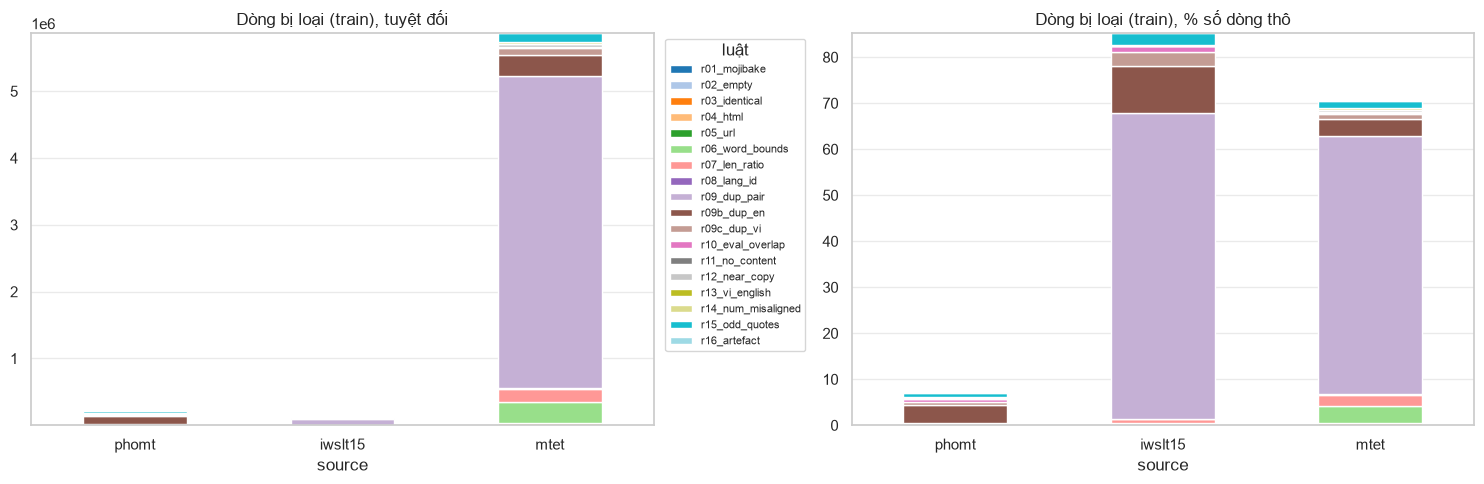

rule,r01_mojibake,r02_empty,r03_identical,r04_html,r05_url,r06_word_bounds,r07_len_ratio,r08_lang_id,r09_dup_pair,r09b_dup_en,r09c_dup_vi,r10_eval_overlap,r11_no_content,r12_near_copy,r13_vi_english,r14_num_misaligned,r15_odd_quotes,r16_artefact
source,,,,,,,,,,,,,,,,,,
phomt,1191,0,139,26,271,4834,5253,1003,825,119428,18078,20840,227,2616,1,5104,31127,612
iwslt15,2,151,121,0,2,506,996,10,88681,13704,3933,1783,34,36,0,311,3279,0
mtet,8650,528,31802,0,4,305896,203099,13593,4664749,314465,98943,18122,9108,35455,0,28322,133590,54


,split,source,raw_rows,kept,retention_pct
9,test,ALL,22955,20259,88.26
12,test,ALL_excl_mtet_eval,20419,20259,99.22
7,test,iwslt15,1268,1189,93.77
8,test,mtet,2536,0,0.00
6,test,phomt,19151,19070,99.58
10,train,ALL,11439022,5247518,45.87
14,train,ALL_excl_mtet_eval,11439022,5247518,45.87
1,train,iwslt15,133317,19768,14.83
2,train,mtet,8327706,2461326,29.56
0,train,phomt,2977999,2766424,92.90


Chú thích: MTet valid/test có retention 0.00% vì chúng là IWSLT tst2012/tst2013 lặp lại ở cả hai hướng dịch (3,106 = 2 x 1,553 dòng và 2,536 = 2 x 1,268 dòng) nên bị dedup nội bộ split theo ưu tiên IWSLT. Dòng ALL_excl_mtet_eval là retention của valid/test khi bỏ các dòng MTet này khỏi cả tử và mẫu. Test còn bị loại thêm các cặp/câu EN trùng valid (r10_valid_overlap).


In [17]:
rl = LOG.table()
tr = rl[rl.split == 'train']
piv = tr.pivot_table(index='source', columns='rule', values='dropped', aggfunc='sum', fill_value=0).reindex(PRIORITY)
n_in = pd.Series({s: LOG.n_in[(s, 'train')] for s in PRIORITY})
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
piv.plot.bar(stacked=True, ax=ax[0], colormap='tab20', rot=0, title='Dòng bị loại (train), tuyệt đối')
(piv.div(n_in, axis=0) * 100).plot.bar(stacked=True, ax=ax[1], colormap='tab20', rot=0, legend=False, title='Dòng bị loại (train), % số dòng thô')
ax[0].legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=8, title='luật')   # đặt legend ngoài để không che cột
for a in ax:
    a.set_axisbelow(True); a.grid(False); a.grid(axis='y', alpha=.4)
fig.tight_layout(); fig.savefig(FIGS / 'dropped_per_rule.png', dpi=110, bbox_inches='tight'); plt.show()
display(piv)

rows = []
for sp in ('train', 'valid', 'test'):
    for s in PRIORITY:
        a, b = LOG.n_in[(s, sp)], FINAL[sp].get(s, 0)
        rows.append(dict(split=sp, source=s, raw_rows=a, kept=b, retention_pct=100 * b / max(a, 1)))
ret = pd.DataFrame(rows)
tot = ret.groupby('split')[['raw_rows', 'kept']].sum().reset_index().assign(source='ALL')
tot['retention_pct'] = 100 * tot.kept / tot.raw_rows
# dòng phụ: bỏ MTet valid/test (là bản sao hai chiều của IWSLT tst2012/tst2013 nên luôn bị dedup về 0)
ex_mt = ret[ret.source != 'mtet'].groupby('split')[['raw_rows', 'kept']].sum().reset_index().assign(source='ALL_excl_mtet_eval')
ex_mt['retention_pct'] = 100 * ex_mt.kept / ex_mt.raw_rows
ex_mt = pd.concat([ex_mt[ex_mt.split != 'train'],
                   tot[tot.split == 'train'].assign(source='ALL_excl_mtet_eval')], ignore_index=True)   # train: không đổi
retention = pd.concat([ret, tot, ex_mt], ignore_index=True).sort_values(['split', 'source'])
display(retention.round(2))
print('Chú thích: MTet valid/test có retention 0.00% vì chúng là IWSLT tst2012/tst2013 lặp lại ở cả hai hướng dịch '
      '(3,106 = 2 x 1,553 dòng và 2,536 = 2 x 1,268 dòng) nên bị dedup nội bộ split theo ưu tiên IWSLT. '
      'Dòng ALL_excl_mtet_eval là retention của valid/test khi bỏ các dòng MTet này khỏi cả tử và mẫu. '
      'Test còn bị loại thêm các cặp/câu EN trùng valid (r10_valid_overlap).')

### 6.2 Thành phần nguồn của từng split

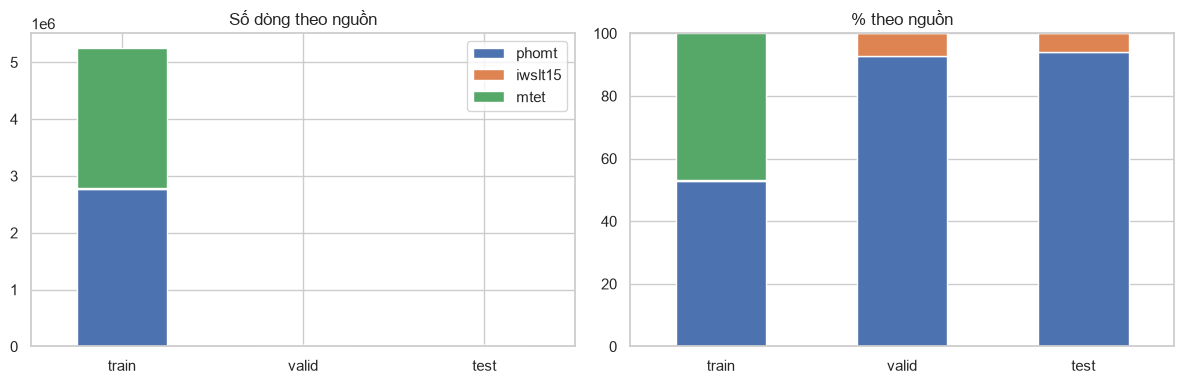

,train,valid,test
phomt,2766424,18705,19070
iwslt15,19768,1486,1189
mtet,2461326,0,0


In [18]:
comp = pd.DataFrame({sp: pd.Series(FINAL[sp]) for sp in ('train', 'valid', 'test')}).fillna(0).reindex(PRIORITY)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
comp.T.plot.bar(stacked=True, ax=ax[0], rot=0, title='Số dòng theo nguồn')
(comp / comp.sum() * 100).T.plot.bar(stacked=True, ax=ax[1], rot=0, legend=False, title='% theo nguồn')
fig.tight_layout(); fig.savefig(FIGS / 'source_composition.png', dpi=110); plt.show()
display(comp.astype(int))

### 6.3 Độ dài trước vs sau làm sạch

Histogram chuẩn hoá (density), "trước" = mẫu thô ở mục 2 (đã bị tokenize nên số từ lớn hơn một chút do `I 'm` tính 2 token), "sau" = train đã sạch. Kỳ vọng: đuôi dài và các mảnh 1 từ bị cắt, thân phân phối gần như giữ nguyên.

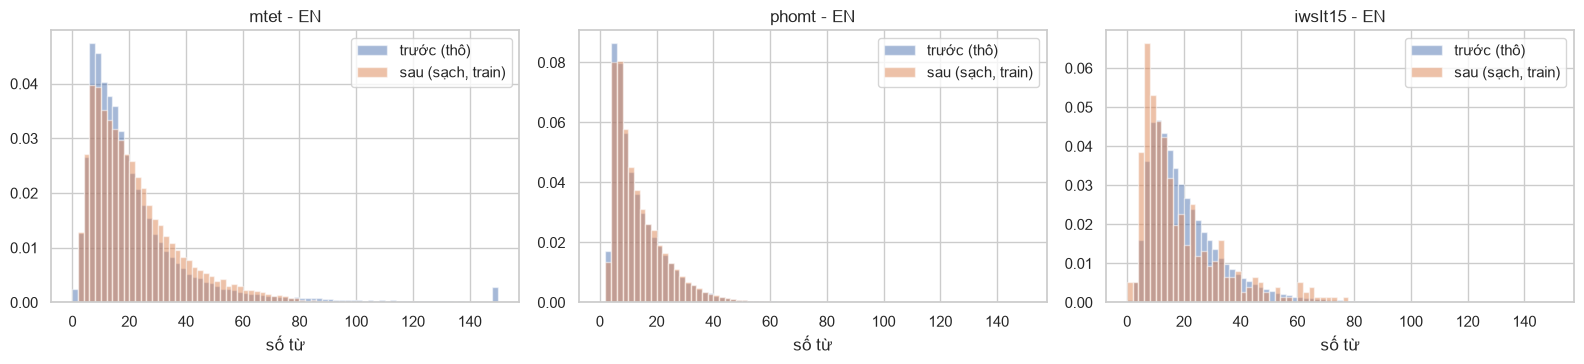

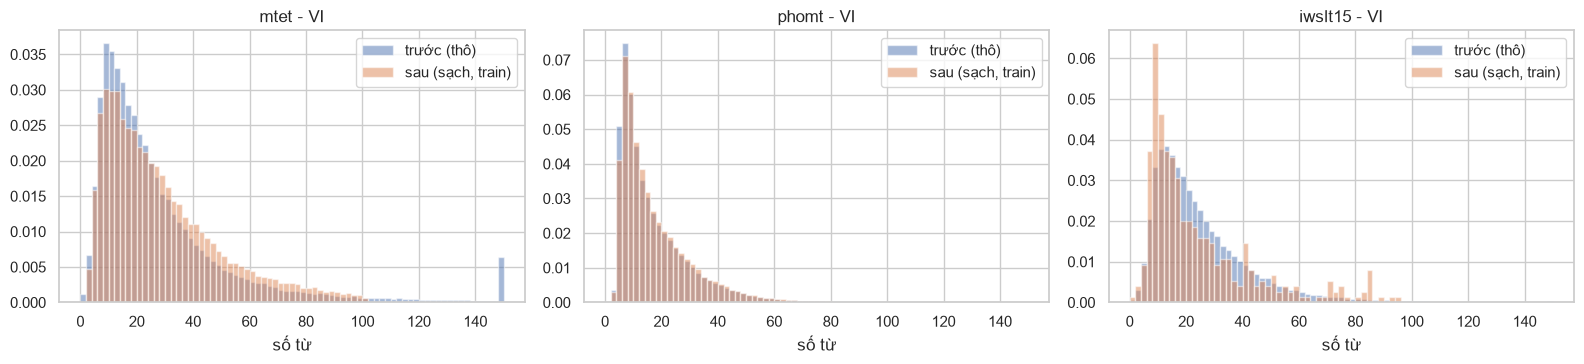

In [19]:
tr_s = KEPT_SAMPLE['train']
for side, name in (('en', 'EN'), ('vi', 'VI')):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=False)
    for ax, s in zip(axes, ['mtet', 'phomt', 'iwslt15']):
        b = np.arange(0, 152, 2)
        ax.hist(eda[s][f'nw_{side}'].clip(upper=150), bins=b, density=True, alpha=.5, label='trước (thô)')
        ax.hist(tr_s.loc[tr_s.source == s, f'nw_{side}'].clip(upper=150), bins=b, density=True, alpha=.5, label='sau (sạch, train)')
        ax.set_title(f'{s} - {name}'); ax.set_xlabel('số từ'); ax.legend()
    fig.tight_layout(); fig.savefig(FIGS / f'len_before_after_{side}.png', dpi=110); plt.show()

### 6.4 EN vs VI: hexbin độ dài và phân phối $r$ sau khi lọc

Dữ liệu sạch phải tập trung quanh đường chéo $n_{vi}\approx1.2\,n_{en}$ và nằm giữa hai đường $r=0.5$ và $r=2.5$.

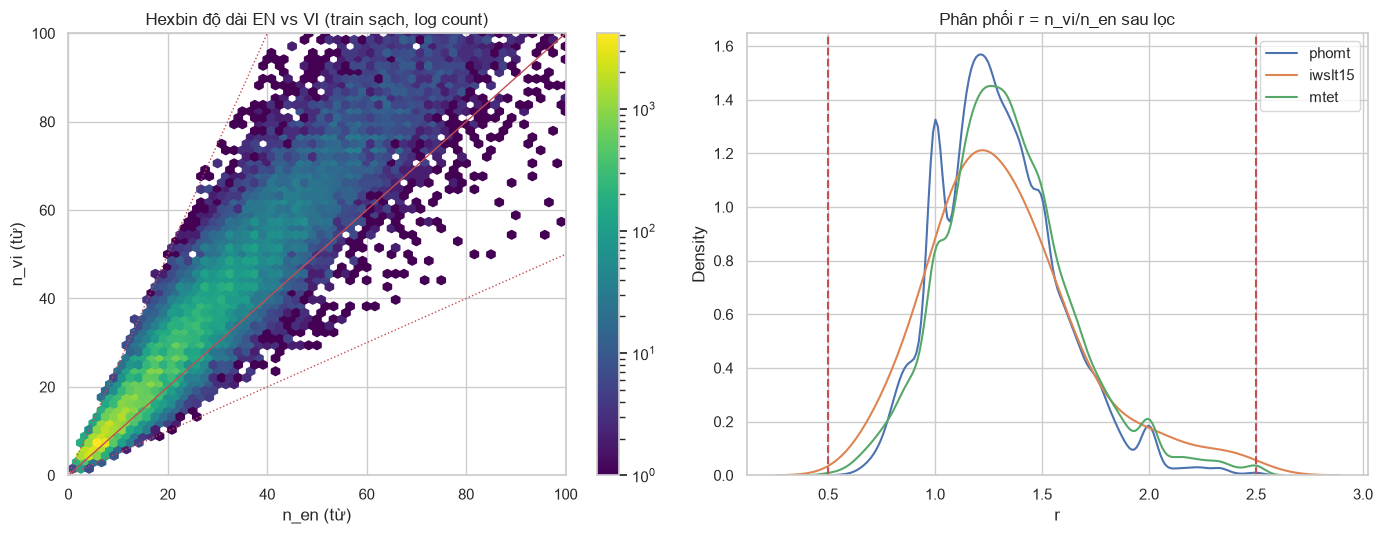

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
hb = ax[0].hexbin(tr_s.nw_en, tr_s.nw_vi, gridsize=60, bins='log', extent=(0, 100, 0, 100), cmap='viridis')
xs = np.array([0, 100])
for rr, st in ((TRAIN_BOUNDS['r_lo'], ':'), (1.0, '-'), (TRAIN_BOUNDS['r_hi'], ':')):
    ax[0].plot(xs, rr * xs, 'r' + st, lw=1)
ax[0].set_xlim(0, 100); ax[0].set_ylim(0, 100)
ax[0].set_xlabel('n_en (từ)'); ax[0].set_ylabel('n_vi (từ)'); ax[0].set_title('Hexbin độ dài EN vs VI (train sạch, log count)')
fig.colorbar(hb, ax=ax[0])
rr_ = tr_s.nw_vi / tr_s.nw_en.clip(lower=1)
for s in PRIORITY:
    sns.kdeplot(rr_[tr_s.source == s].clip(upper=4), ax=ax[1], label=s, bw_adjust=1.2)
ax[1].axvline(TRAIN_BOUNDS['r_lo'], c='r', ls='--'); ax[1].axvline(TRAIN_BOUNDS['r_hi'], c='r', ls='--')
ax[1].set_title('Phân phối r = n_vi/n_en sau lọc'); ax[1].set_xlabel('r'); ax[1].legend()
fig.tight_layout(); fig.savefig(FIGS / 'hexbin_and_ratio_after.png', dpi=110); plt.show()

### 6.5 15 cặp ngẫu nhiên mỗi nguồn (để mắt người kiểm tra)

In [21]:
for s in PRIORITY:
    print(f'\n=========== {s} ===========')
    g = tr_s[tr_s.source == s]
    display(g.sample(min(15, len(g)), random_state=SEED)[['en', 'vi']].reset_index(drop=True))


=========== phomt ===========


,en,vi
0,"Adjust, my child.","Bĩnh tĩnh, con ta."
1,This very basic shift in my physical orientation helped me shift my perspective in relation to the glacier.,Sự chuyển đổi rất cơ bản trong định hướng về thể chất giúp tôi thay đổi quan điểm của mình trong mối quan hệ với băng.
2,"Spread the metaldehyde thinly, never in piles, which pets can mistake for food.","Rải lớp mỏng metaldehyde, không được để thành đống, vì thú nuôi sẽ nhầm là thức ăn."
3,We made it thinner.,Làm cho nó mỏng hơn một tý.
4,"Eating a little faster than normal can help you to consume more food before you start to feel full, thus increasing your calorie intake.","Ăn nhanh hơn một chút so với bình thường có thể giúp bạn ăn được nhiều hơn trước khi bắt đầu thấy no, nhờ đó tăng lượng calo dung nạp."
5,"Chung also produced her debut album, Sharon, mostly recorded in the United Kingdom in 1974 due to a musicians strike in Jamaica.","Chung cũng sản xuất album đầu tay của cô, Sharon, hầu hết được thu âm tại Vương quốc Anh vào năm 1974 do một cuộc đình công của các nhạc sĩ ở Jamaica."
6,You can't compare unemployment to a cat four hurricane.,Ngài không thể so sánh thất nghiệp với một cơn bão cấp bốn được.
7,Timing is key to starting a great conversation.,Thời điểm phù hợp chính là chìa khoá cho một cuộc trò chuyện tuyệt vời.
8,Plan your workouts right before or right after classes so that you know your day isn't done until you've completed everything you need to.,Lên kế hoạch tập luyện ngay trước khi đến lớp hoặc ngay sau khi tan học để bạn biết rằng một ngày của mình chưa qua cho đến khi bạn hoàn thành mọi việc cần ...
9,Because of Your Highness' dark complexion?,Vì màu da sậm của ông à?



=========== iwslt15 ===========


,en,vi
0,"Stacey Kramer offers a moving, personal, 3-minute parable that shows how an unwanted experience -- frightening, traumatic, costly -- can turn out to be a pr...","Câu chuyện dài 3 phút đầy riêng tư và xúc động của Stacey Kramer cho ta thấy làm thế nào mà một trải nghiệm bất ngờ, khủng khiếp, đau buồn, hao tiền tốn của..."
1,"This is all their movies. We've got about 60 movies that these kids have made, and they're quite incredible.",Đây là phim của các em. Có khoảng 60 bộ phim mà các em này đã làm. Và chúng khá xuất sắc đấy.
2,"She goes, ""What about dogs?""","Rồi nó hỏi ""Thế chó thì sao ạ?"""
3,"I want to thank you, thank you Thank you, thank you Thank you, thank you Thank you, thank you I want to thank you, thank you It works better, right?","Tôi muốn cám ơn, cám ơn Cám ơn, cám ơn Cám ơn, cám ơn Cám ơn, cám ơn Tôi muốn cám ơn, cám ơn Như thế này tốt hơn, đúng không?"
4,Girl: 581. This house is 581...,Bé gái: 581. Ngôi nhà này là 581...
5,"Wait, wait, wait, not doing anything?","""Khoan, từ từ, không làm gì ư?"""
6,"It's particularly important -- this isn't on the World Wide Web, is it? I'm about to get fired -- it's particularly important that you never put the quality...","Điều đặc biệt quan trọng là -- clip này sẽ không được post trên Internet, phải không? Chắc tôi sắp bị đuổi việc rồi -- điều đặc biệt quan trọng là bạn đừng ..."
7,"And I try to live my dream -- well, actually, it was never my dream, but it sounds so good.","Và tôi cố sống giấc mơ của tôi -- nhưng thực ra, đó chưa bao giờ là giấc mơ của tôi, nhưng điều đó nghe thật tuyệt."
8,"Time is. Time has come. ' ' White is leaving, ' Steve said somberly.","Thời gian. Đã đến lúc. ' ' White sẽ rời đi, ' Steve đã nói một cách buồn rầu."
9,OK.,OK



=========== mtet ===========


,en,vi
0,"By the time Bad was released, Thriller had sold millions, raising expectations for the new album.","Trước khi Bad được phát hành, Thriller đã bán được hàng triệu đĩa, đưa ra những sự kì vọng cho album mới."
1,"""US veteran arrested over Fort Lauderdale shooting"".","Truy cập ngày 7 tháng 1 năm 2017. ^ ""US veteran arrested over Fort Lauderdale shooting""."
2,"which raises the question, ""Is this how they think?""","Điều này đặt ra câu hỏi: ""Họ cũng tư duy như vậy ư?"""
3,"I sink down on the bed across from Tori. She is sitting up, her leg propped on a stack of pillows. '","Tôi ngồi phịch xuống cái giường đối diện cô Tori. Cô ngồi dậy, chân gác lên một chồng gối. '"
4,"he could be hurt.-(laughs) I punched a guy in the stomach and I recorded on high speed. Now I was trying to figure out how to transition to it, but you kind...","ông ấy có thể sẽ bị thương.-Destin: Tôi đã đấm vào dạ dày một anh chàng và ghi lại bằng camera tốc độ cao. Giờ tôi đang tìm cách chuyển cảnh, nhưng cậu có v..."
5,b) Receipt of money transferred to accounts of companies in commercial institutions-in case of founding shareholders/founding members/owners/partners/contri...,b) Giấy nộp tiền vào tài khoản của công ty mở tại ngân hàng thương mại-đối với cổ đông sáng lập/thành viên sáng lập/chủ sở hữu/thành viên hợp danh/thành viê...
6,e) Provide data deviating from test results that cause serious consequences to construction quality;,"e) Cung cấp số liệu sai lệch so với kết quả thí nghiệm, gây hậu quả nghiêm trọng về chất lượng công trình xây dựng."
7,"I was familiar with Kirlian photography and the studies in parapsychology at U.C.L.A., where research has indicated each living person projects their own co...","Tôi quen thuộc với tấm hình Kirlian 83 và những nghiên cứu trong ngành cận tâm lý tại U.C.L.A, nơi mà sự khảo cứu đã chỉ ra rằng, mỗi con người đang sống đề..."
8,b) Operate the reservoir to discharge water to lower Thu Bon river:,b) Vận hành xả nước về hạ lưu sông Thu Bồn:
9,Tapping it opens the AssistiveTouch menu.,"Khi bạn nhấn vào, trình đơn AssistiveTouch sẽ mở ra."


### 6.6 Top-20 token thường gặp theo phía và nguồn

Kiểm tra nhanh xem còn "rác tokenize" (ví dụ `'s`, `n't`, `&apos;`) lọt vào top, và hai phía có phân phối từ hợp lý (từ chức năng, dấu câu).

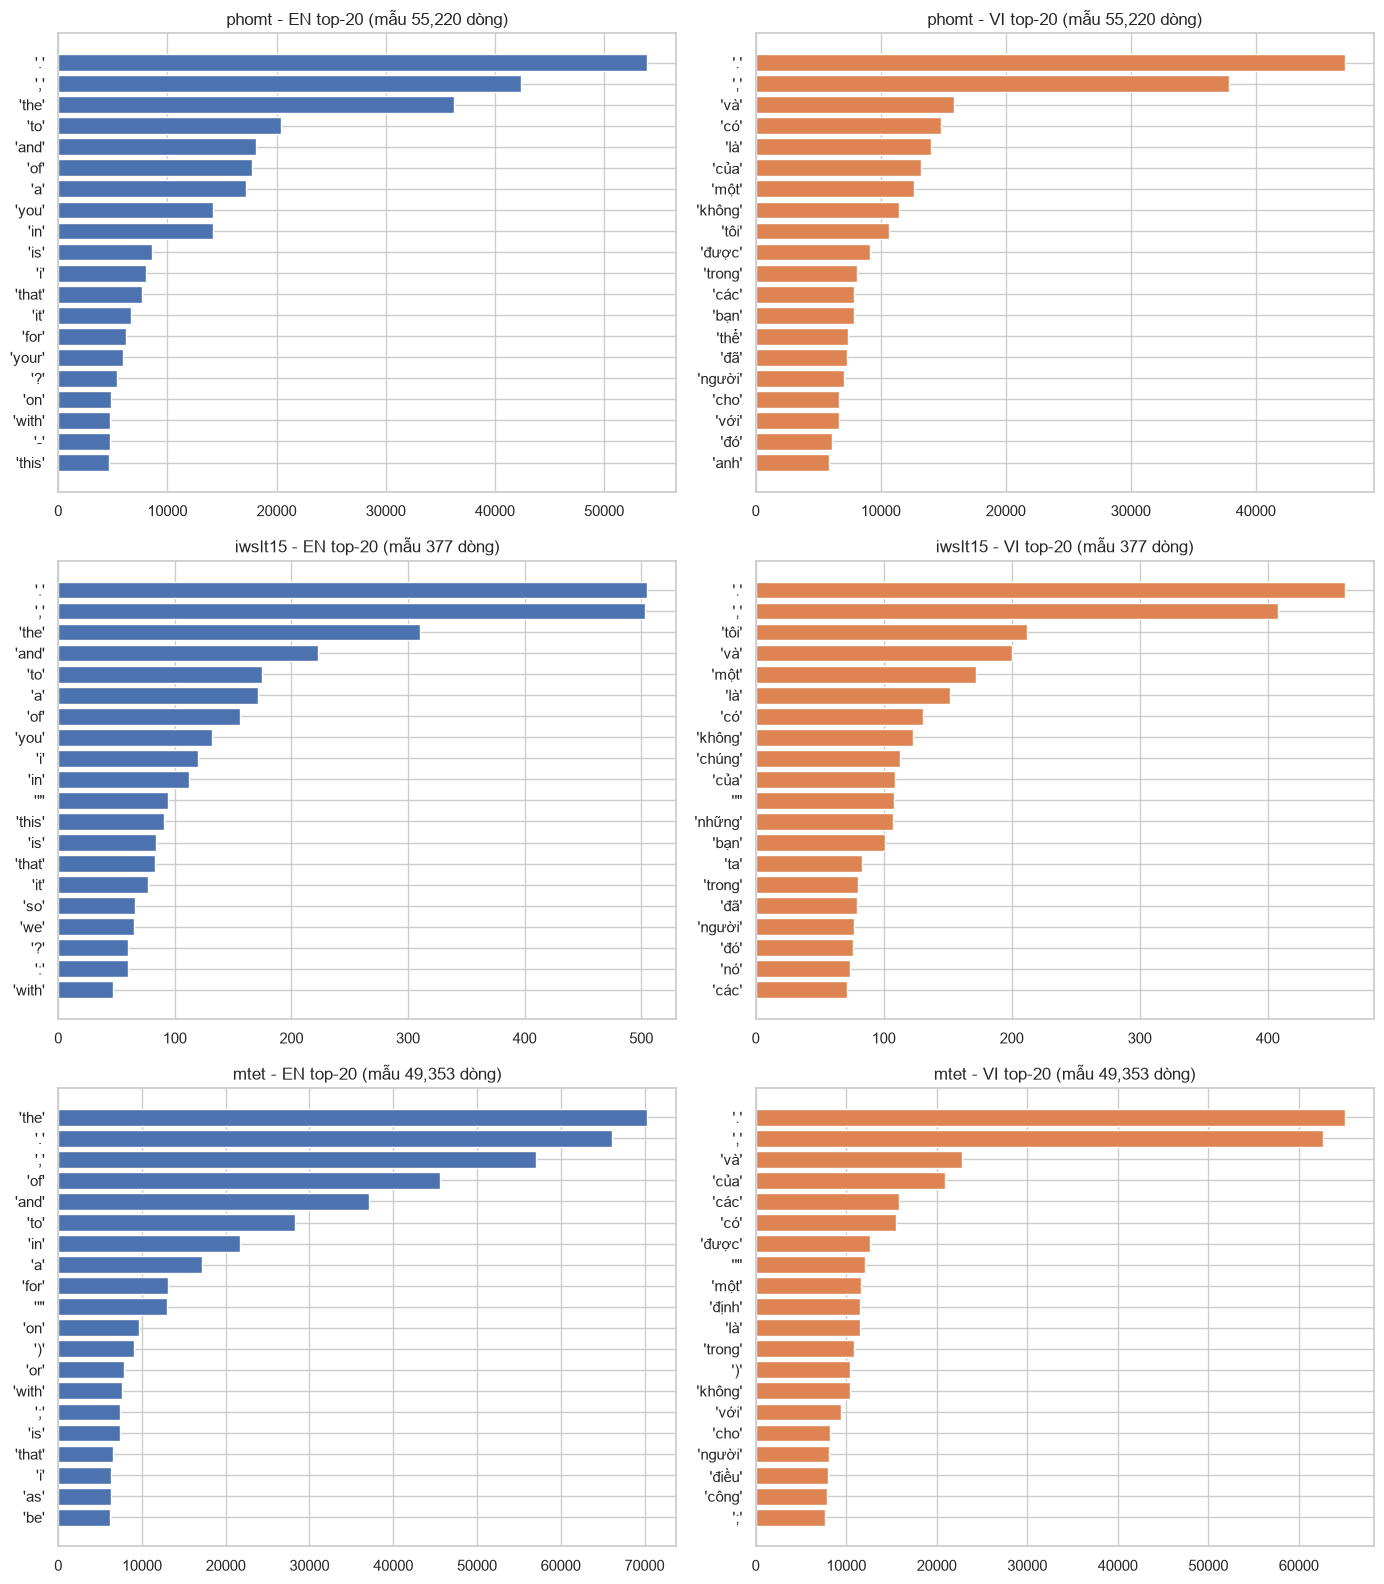

In [22]:
TOK_RX = re.compile(r"[\w'’\-]+|[^\w\s'’\-]")   # giữ nguyên 's, n't, -, don't ... để rác tokenize (nếu còn) hiện ra trong top
def top_tokens(texts, k=20):
    '''Top-k token (chữ thường; từ giữ nguyên dấu nháy đơn/gạch nối bên trong, dấu câu tách riêng) của một dãy câu.'''
    c = collections.Counter()
    for t in texts:
        c.update(TOK_RX.findall(t.lower()))
    return c.most_common(k)

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
for i, s in enumerate(PRIORITY):
    g = tr_s[tr_s.source == s]
    for j, side in enumerate(('en', 'vi')):
        tt = top_tokens(g[side])
        axes[i, j].barh([repr(t) for t, _ in tt][::-1], [c for _, c in tt][::-1], color=sns.color_palette()[j])
        axes[i, j].tick_params(axis='y', labelsize=11)
        axes[i, j].set_title(f'{s} - {side.upper()} top-20 (mẫu {len(g):,} dòng)')
fig.tight_layout(); fig.savefig(FIGS / 'top_tokens.png', dpi=110); plt.show()

### 6.7 Bằng chứng cho các luật mới trên toàn bộ pipeline

Số câu mojibake **sửa** vs **loại** theo nguồn/split, 20 ví dụ đã sửa, 20 ví dụ dedup theo phía (dòng bị loại cạnh dòng được giữ cùng khoá), và số dòng ở valid/test vi phạm các luật chỉ-train (được giữ).


In [23]:
rl = LOG.table()
# ---- mojibake: toàn bộ pipeline ----
rows = []
for sp in ('train', 'valid', 'test'):
    for s in PRIORITY:
        rows.append(dict(split=sp, source=s, raw_rows=LOG.n_in[(s, sp)], fixed_en=LOG.repaired[(s, sp, 'en')], fixed_vi=LOG.repaired[(s, sp, 'vi')],
                         dropped_rows=int(rl[(rl.source == s) & (rl.split == sp) & (rl.rule == 'r01_mojibake')].dropped.sum())))
moji_tbl = pd.DataFrame(rows)
display(moji_tbl)
print('Tổng: sửa', int(moji_tbl[['fixed_en', 'fixed_vi']].sum().sum()), 'câu; loại', int(moji_tbl.dropped_rows.sum()), 'dòng')
rr = np.random.default_rng(SEED)
print('\n--- 20 ví dụ mojibake đã sửa trong pipeline (train) ---')
fx = [r for r in LOG.repair_ex if r[1] == 'train']
for i in rr.permutation(len(fx))[:20]:
    s, sp, side, a, b = fx[i]
    print(f'  {s}/{side}: {a[:90]!r}\n          -> {b[:90]!r}')

# ---- dedup theo phía: ví dụ (bị loại <- giữ lại) ----
print('\n--- r09b_dup_en / r09c_dup_vi: 20 ví dụ mỗi luật (dòng bị loại; dòng được giữ với cùng khoá) ---')
for rule in ('r09b_dup_en', 'r09c_dup_vi'):
    print(f'\n== {rule} ==')
    for r, a, b in [x for x in DEDUP_EX if x[0] == rule][:20]:
        print(f'  LOẠI [{a[2]}] EN: {a[0][:90]!r}\n               VI: {a[1][:90]!r}\n  GIỮ  [{b[2]}] EN: {b[0][:90]!r}\n               VI: {b[1][:90]!r}')

# ---- luật chỉ áp cho train: đếm trên valid/test (giữ lại) ----
fl = pd.DataFrame([dict(source=s, split=sp, rule=r, flagged_kept=n) for (s, sp, r), n in sorted(LOG.flagged.items())])
if len(fl):
    display(fl.pivot_table(index=['rule'], columns=['split', 'source'], values='flagged_kept', aggfunc='sum', fill_value=0))
print('valid/test: các dòng trên vi phạm luật 14/15/16 nhưng được GIỮ để không làm méo tập đánh giá.')


,split,source,raw_rows,fixed_en,fixed_vi,dropped_rows
0,train,phomt,2977999,17,2,1191
1,train,iwslt15,133317,0,0,2
2,train,mtet,8327706,30128,12,8650
3,valid,phomt,18720,0,0,0
4,valid,iwslt15,1553,0,0,0
5,valid,mtet,3106,0,0,0
6,test,phomt,19151,0,0,0
7,test,iwslt15,1268,0,0,0
8,test,mtet,2536,0,0,0


Tổng: sửa 30159 câu; loại 9843 dòng

--- 20 ví dụ mojibake đã sửa trong pipeline (train) ---
  mtet/en: 'â€ " they will also feel some pride in your choice to be honest.'
          -> '— they will also feel some pride in your choice to be honest.'
  mtet/en: "Determine if you will include an answer such as â€œI don't knowâ€\x9d or â€œNot applicable to"
          -> "Determine if you will include an answer such as “I don't know” or “Not applicable to me. ”"
  mtet/en: "You might say, â€œWhat do you think about the president's new bill, Dad? â€\x9d Look at onlin"
          -> "You might say, “What do you think about the president's new bill, Dad? ” Look at online so"
  mtet/en: "So, instead of, â€˜I want to lose weight, ' you can write, â€˜I want to lose one pound eve"
          -> "So, instead of, ‘I want to lose weight, ' you can write, ‘I want to lose one pound every w"
  mtet/en: 'Make sure they don\'t have a saggy crotchâ€ " this means there is too much fabric and they\''
          

split                 test              valid           
source             iwslt15 mtet phomt iwslt15 mtet phomt
rule                                                    
r14_num_misaligned       8   16    26       3    6    24
r15_odd_quotes          26   52   141      31   62   134
r16_artefact             0    0     3       0    0     3

valid/test: các dòng trên vi phạm luật 14/15/16 nhưng được GIỮ để không làm méo tập đánh giá.


## 7. Kiểm tra bất biến của dữ liệu đầu ra

Đọc lại **chính các file đã ghi** (không dùng biến trong bộ nhớ) và `assert`:

- không có dòng rỗng; mọi dòng ở dạng NFC (`unicodedata.is_normalized`);
- số dòng `.en` = `.vi` = số dòng `.parquet` cho từng split;
- không có cặp trùng trong train, **không có khoá EN (hay khoá VI) trùng nhau** trong train;
- train $\cap$ (valid $\cup$ test) $=\emptyset$ theo cặp, theo câu EN **và theo câu VI** (khoá chuẩn hoá `norm_key`: casefold, bỏ dấu câu/khoảng trắng);
- valid $\cap$ test $=\emptyset$ theo cặp, câu EN và câu VI (đã loại khỏi test ở bước dựng eval).

Phần kiểm tra dùng băm của Python (`hash`) thay vì băm pandas của pipeline để đối chứng độc lập.


In [24]:
import array

def read_pairs(split):
    '''Trả về danh sách cặp (en, vi) của split nhỏ (valid/test).'''
    pairs = []
    with open(CLEAN / f'{split}.en', encoding='utf-8', newline='\n') as fe, open(CLEAN / f'{split}.vi', encoding='utf-8', newline='\n') as fv:
        for le, lv in zip(fe, fv):
            pairs.append((le[:-1], lv[:-1]))
    return pairs

def audit_split(split, forbid_pairs=None, forbid_en=None, forbid_vi=None):
    '''Duyệt streaming: rỗng, NFC, xuống dòng, trùng cặp; với train thêm: không có khoá EN/VI trùng nhau, và không giao với tập cấm
    (cặp, khoá EN chuẩn hoá, khoá VI chuẩn hoá của valid/test). Trả về số dòng.'''
    n, seen = 0, set()
    ke, kv = array.array('q'), array.array('q')
    with open(CLEAN / f'{split}.en', encoding='utf-8', newline='\n') as fe, open(CLEAN / f'{split}.vi', encoding='utf-8', newline='\n') as fv:
        for le, lv in zip(fe, fv):
            assert le.endswith('\n') and lv.endswith('\n')
            le, lv = le[:-1], lv[:-1]
            assert le.strip() and lv.strip(), f'{split}: dòng rỗng ở {n}'
            assert '\r' not in le and '\r' not in lv
            assert unicodedata.is_normalized('NFC', le) and unicodedata.is_normalized('NFC', lv), f'{split}: không NFC ở {n}'
            h = hash((le, lv))
            assert h not in seen, f'{split}: trùng cặp ở {n}: {le[:60]!r}'
            seen.add(h)
            if forbid_pairs is not None:
                te, tv = norm_key(le), norm_key(lv)
                assert (le, lv) not in forbid_pairs, f'{split}: rò rỉ cặp với valid/test ở {n}: {le[:60]!r}'
                assert te not in forbid_en, f'{split}: rò rỉ câu EN với valid/test ở {n}: {le[:60]!r}'
                assert tv not in forbid_vi, f'{split}: rò rỉ câu VI với valid/test ở {n}: {lv[:60]!r}'
                ke.append(hash(te) & 0x7FFFFFFFFFFFFFFF); kv.append(hash(tv) & 0x7FFFFFFFFFFFFFFF)
            n += 1
    if forbid_pairs is not None:
        assert len(np.unique(np.frombuffer(ke, dtype=np.int64))) == n, f'{split}: còn khoá EN trùng'
        assert len(np.unique(np.frombuffer(kv, dtype=np.int64))) == n, f'{split}: còn khoá VI trùng'
    return n

eval_pairs = {sp: read_pairs(sp) for sp in ('valid', 'test')}
forbid_pairs = set(eval_pairs['valid']) | set(eval_pairs['test'])
forbid_en = {norm_key(e) for e, _ in forbid_pairs}
forbid_vi = {norm_key(v) for _, v in forbid_pairs}
AUDIT = {}
for sp in ('valid', 'test', 'train'):
    t0 = time.time()
    n_lines = audit_split(sp, *((forbid_pairs, forbid_en, forbid_vi) if sp == 'train' else (None, None, None)))
    n_en = sum(1 for _ in open(CLEAN / f'{sp}.en', encoding='utf-8', newline='\n'))
    n_vi = sum(1 for _ in open(CLEAN / f'{sp}.vi', encoding='utf-8', newline='\n'))
    n_pq = pq.ParquetFile(CLEAN / f'{sp}.parquet').metadata.num_rows
    assert n_en == n_vi == n_pq == n_lines == sum(FINAL[sp].values()), (sp, n_en, n_vi, n_pq, n_lines)
    AUDIT[sp] = n_lines
    extra = ', khoá EN/VI duy nhất, không giao valid/test (cặp, EN, VI)' if sp == 'train' else ''
    print(f'{sp:6s}: {n_lines:>10,} dòng | OK (không rỗng, NFC, en=vi=parquet, không trùng cặp{extra}) | {time.time() - t0:.0f}s')
vt_pairs = set(eval_pairs['valid']) & set(eval_pairs['test'])
vt_en = {norm_key(e) for e, _ in eval_pairs['valid']} & {norm_key(e) for e, _ in eval_pairs['test']}
vt_vi = {norm_key(v) for _, v in eval_pairs['valid']} & {norm_key(v) for _, v in eval_pairs['test']}
print('Giao valid∩test: số cặp =', len(vt_pairs), '| số câu EN (khoá chuẩn hoá) =', len(vt_en), '| số câu VI =', len(vt_vi))
assert not vt_pairs and not vt_en and not vt_vi, f'valid ∩ test không rỗng: {len(vt_pairs)} cặp, {len(vt_en)} EN, {len(vt_vi)} VI'
head = pq.ParquetFile(CLEAN / 'train.parquet').read_row_group(0).slice(0, 200).to_pandas()
with open(CLEAN / 'train.en', encoding='utf-8', newline='\n') as fe, open(CLEAN / 'train.vi', encoding='utf-8', newline='\n') as fv:
    for i, (le, lv) in enumerate(zip(fe, fv)):
        if i >= len(head):
            break
        assert (le[:-1], lv[:-1]) == (head.en[i], head.vi[i])
print('Train: .en/.vi khớp .parquet ở 200 dòng đầu; train ∩ (valid ∪ test) = ∅ (cặp, câu EN, câu VI); khoá EN và khoá VI duy nhất: OK')


valid :     20,191 dòng | OK (không rỗng, NFC, en=vi=parquet, không trùng cặp) | 0s
test  :     20,259 dòng | OK (không rỗng, NFC, en=vi=parquet, không trùng cặp) | 0s
train :  5,247,518 dòng | OK (không rỗng, NFC, en=vi=parquet, không trùng cặp, khoá EN/VI duy nhất, không giao valid/test (cặp, EN, VI)) | 72s
Giao valid∩test: số cặp = 0 | số câu EN (khoá chuẩn hoá) = 0 | số câu VI = 0
Train: .en/.vi khớp .parquet ở 200 dòng đầu; train ∩ (valid ∪ test) = ∅ (cặp, câu EN, câu VI); khoá EN và khoá VI duy nhất: OK


## 7b. Audit độc lập: trước vs sau

Đo lại các lỗi đã phát hiện ở bản train v1 bằng các regex **viết riêng** (không gọi lại hàm của luật lọc): mojibake (`â€`, `Ã©`, `Â°`, C1, `U+FFFD`), dấu tiếng Việt trong EN, số rời nhau, nháy kép lẻ, thiếu nội dung, EN $\approx$ VI, khoá EN/VI trùng, tàn dư tokenize và gạch nối tách rời. Cột "trước" đọc từ `data/clean/audit_before.json` (đo trên train v1 trước khi thêm các luật mới); cột "sau" đo ngay trên file vừa ghi. **Mục tiêu cho train**: mọi chỉ số lỗi $=0$, riêng dấu VN trong EN $<0.1\%$; hai dòng "(tham khảo)" chỉ để theo dõi. Nếu không đạt thì `assert` dừng notebook.


In [25]:
# ---- Audit ĐỘC LẬP: viết lại riêng các regex/phép đo, KHÔNG gọi lại hàm của luật lọc (chỉ dùng chung hằng số ngưỡng) ----
import difflib, array
A_MOJI = re.compile('â€|Ã[\x80-\xbf¡-¿]|Â[\xa0-\xbf]|[\x80-\x9f]|�')             # mojibake (regex của audit v1) + C1 + U+FFFD
A_VI_ANY = re.compile('[àáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđ]', re.I)
A_SPACED_HY = re.compile(r'[^\W\d_] - [^\W\d_]')
A_ART = re.compile(r"\s'(?:s|re|ve|ll|d|m)\b|\sn't\b|\w\s't\b")
A_SLASH = re.compile(r'\w / \w')
A_THOU = re.compile(r'(?<![0-9])([0-9]{1,3})((?:(?:, |[ ,.])[0-9]{3})+)(?![0-9])')
A_ENSTOP = {'the', 'and', 'of', 'is', 'are', 'was', 'were', 'that', 'this', 'with', 'for', 'you', 'have', 'has', 'not', 'but', 'from',
            'they', 'their', 'which', 'will', 'would', 'there', 'what', 'when', 'your', 'been'}

def _a_nums(x):
    x = A_THOU.sub(lambda m: m.group(1) + re.sub(r'\D', '', m.group(2)), x)       # 1,000 / 1.000 / 1 000 / 1, 000 -> 1000
    return set(re.findall(r'[0-9]+', x))

def _a_odd_quote(x):
    if '"' not in x:
        return False
    return sum(1 for i, c in enumerate(x) if c == '"' and not (i > 0 and x[i - 1] in '0123456789')) % 2 == 1

def _a_diac_lower(x):
    n = 0
    for tok in x.split():
        w = tok.strip('()[]{}"\'.,;:!?-–—“”‘’')
        if w and w[0].islower():
            n += len(A_VI_ANY.findall(w))
    return n

def _a_near_copy(en, vi):
    if len(en) <= NEAR_COPY_MIN_CHARS:
        return False
    a, b = en.casefold(), vi.casefold()
    la, lb = ''.join(c for c in a if c.isalpha()), ''.join(c for c in b if c.isalpha())
    if la == lb:
        return True
    wa, wb = set(re.findall(r'\w+', a)), set(re.findall(r'\w+', b))
    if not wa | wb or len(wa & wb) / len(wa | wb) < 0.5:
        return False
    return difflib.SequenceMatcher(None, a, b, autojunk=False).ratio() > NEAR_COPY_RATIO

def _a_few_letters(x):
    return sum(c.isalpha() for c in x) < 2 or re.fullmatch(r'[(\[]?(?:[0-9]{1,3}|[A-Za-z]|[ivxIVX]{1,4})[.)\]]+', x) is not None

def _a_key(x):
    return hash(re.sub(r'[\W_]+', '', x.casefold())) & 0x7FFFFFFFFFFFFFFF

AUDIT_KEYS = [('moji_en', 'EN: mojibake (â€, Ã©, Â°, C1)'), ('moji_vi', 'VI: mojibake (â€, Ã©, Â°, C1)'),
              ('fffd', 'dòng có U+FFFD (EN hoặc VI)'),
              ('en_diac_lower', 'EN: >=3 ký tự dấu VN trong từ thường & tỉ lệ >0.01'), ('en_diac_any', '(tham khảo) EN: có >=1 ký tự dấu VN'),
              ('num_disjoint', 'số hai phía rời nhau hoàn toàn'), ('odd_quote', 'số dấu " lẻ (EN hoặc VI, trừ dấu inch)'),
              ('few_letters', '<2 chữ cái hoặc chỉ là số thứ tự'), ('near_copy', 'EN ≈ VI (sao chép)'), ('identical', 'EN == VI (casefold)'),
              ('vi_english', 'VI không dấu, >=3 từ chức năng tiếng Anh'),
              ('dup_en_key', 'khoá EN trùng (casefold, bỏ dấu câu/trắng)'), ('dup_vi_key', 'khoá VI trùng'),
              ('art_apos', "tàn dư ` 's` / ` n't` rời"), ('art_slash', 'tàn dư `w / w`'),
              ('spaced_hyphen_en', '(tham khảo) EN: gạch nối tách rời giữa chữ cái')]

def audit_metrics(parquet_path, batch=200_000):
    '''Đo các lỗi dữ liệu trên một file parquet (en, vi) bằng regex độc lập. Trả về dict {khoá: số dòng} + 'rows'.'''
    c = collections.Counter()
    k_en, k_vi = array.array('q'), array.array('q')
    for b in pq.ParquetFile(parquet_path).iter_batches(batch_size=batch, columns=['en', 'vi']):
        for en, vi in zip(b.column('en').to_pylist(), b.column('vi').to_pylist()):
            c['rows'] += 1
            me, mv = A_MOJI.search(en) is not None, A_MOJI.search(vi) is not None
            c['moji_en'] += me; c['moji_vi'] += mv
            c['fffd'] += ('�' in en) or ('�' in vi)
            n_any = len(A_VI_ANY.findall(en))
            c['en_diac_any'] += n_any > 0
            if n_any >= 3:
                n = _a_diac_lower(en)
                c['en_diac_lower'] += n >= 3 and n / max(len(en), 1) > 0.01
            na, nb = _a_nums(en), _a_nums(vi)
            c['num_disjoint'] += bool(na) and bool(nb) and na.isdisjoint(nb)
            c['odd_quote'] += _a_odd_quote(en) or _a_odd_quote(vi)
            c['few_letters'] += _a_few_letters(en) or _a_few_letters(vi)
            c['near_copy'] += _a_near_copy(en, vi)
            c['identical'] += en.casefold() == vi.casefold()
            if A_VI_ANY.search(vi) is None:
                c['vi_english'] += sum(w in A_ENSTOP for w in re.findall(r'[a-z]+', vi.lower())) >= 3
            k_en.append(_a_key(en)); k_vi.append(_a_key(vi))
            c['art_apos'] += (A_ART.search(en) is not None) or (A_ART.search(vi) is not None)
            c['art_slash'] += (A_SLASH.search(en) is not None) or (A_SLASH.search(vi) is not None)
            c['spaced_hyphen_en'] += A_SPACED_HY.search(en) is not None
    c['dup_en_key'] = c['rows'] - len(np.unique(np.frombuffer(k_en, dtype=np.int64)))
    c['dup_vi_key'] = c['rows'] - len(np.unique(np.frombuffer(k_vi, dtype=np.int64)))
    return {k: int(c[k]) for k in ['rows'] + [k for k, _ in AUDIT_KEYS]}


In [26]:
t0 = time.time()
AUD_AFTER = {sp: audit_metrics(CLEAN / f'{sp}.parquet') for sp in ('train', 'valid', 'test')}
BEFORE_PATH = CLEAN / 'audit_before.json'
AUD_BEFORE = json.load(open(BEFORE_PATH, encoding='utf-8')) if BEFORE_PATH.exists() else None
print(f'audit xong sau {time.time() - t0:.0f}s | "trước" = {"train v1 (audit_before.json)" if AUD_BEFORE else "không có"}'
      f'{" (CHÚ Ý: SAMPLE=True nên so sánh với bản FULL không có ý nghĩa)" if SAMPLE else ""}')

def _fmt(d, k):
    return f'{d[k]:,} ({100 * d[k] / max(d["rows"], 1):.3f}%)' if d else '-'
rows = [dict(metric=desc, **{f'{sp} {when}': _fmt((AUD_BEFORE or {}).get(sp) if when == 'trước' else AUD_AFTER[sp], k)
                             for sp in ('train', 'valid', 'test') for when in ('trước', 'sau')}) for k, desc in AUDIT_KEYS]
rows.insert(0, dict(metric='số dòng', **{f'{sp} {when}': f'{((AUD_BEFORE or {}).get(sp) if when == "trước" else AUD_AFTER[sp])["rows"]:,}' if (when == 'sau' or AUD_BEFORE) else '-'
                                         for sp in ('train', 'valid', 'test') for when in ('trước', 'sau')}))
AUDIT_TABLE = pd.DataFrame(rows)
display(AUDIT_TABLE)

# mục tiêu cho TRAIN (valid/test chỉ báo cáo): mọi chỉ số lỗi = 0, riêng dấu VN trong EN cho phép < 0.1%
tr = AUD_AFTER['train']
ZERO = ['moji_en', 'moji_vi', 'fffd', 'num_disjoint', 'odd_quote', 'few_letters', 'near_copy', 'identical', 'vi_english',
        'dup_en_key', 'dup_vi_key', 'art_apos', 'art_slash']
bad = {k: tr[k] for k in ZERO if tr[k] != 0}
assert not bad, f'audit train: còn lỗi {bad}'
assert tr['en_diac_lower'] / tr['rows'] < 0.001, f'EN còn dấu VN: {tr["en_diac_lower"]}'
print('AUDIT ĐẠT: train có', {k: 0 for k in ZERO}, '| EN dấu VN (từ thường):', tr['en_diac_lower'], '| gạch nối tách rời còn lại (giới hạn đã biết):',
      f'{tr["spaced_hyphen_en"]:,} dòng = {100 * tr["spaced_hyphen_en"] / tr["rows"]:.2f}% train')
for sp in ('valid', 'test'):
    print(f'{sp} (chỉ báo cáo, không lọc):', {k: v for k, v in AUD_AFTER[sp].items() if k in ("num_disjoint", "odd_quote", "art_apos", "dup_en_key", "dup_vi_key", "near_copy")})


audit xong sau 377s | "trước" = train v1 (audit_before.json)


,metric,train trước,train sau,valid trước,valid sau,test trước,test sau
0,số dòng,"5,964,727","5,247,518","20,203","20,191","20,308","20,259"
1,"EN: mojibake (â€, Ã©, Â°, C1)","14,412 (0.242%)",0 (0.000%),0 (0.000%),0 (0.000%),0 (0.000%),0 (0.000%)
2,"VI: mojibake (â€, Ã©, Â°, C1)",86 (0.001%),0 (0.000%),0 (0.000%),0 (0.000%),0 (0.000%),0 (0.000%)
3,dòng có U+FFFD (EN hoặc VI),"2,647 (0.044%)",0 (0.000%),0 (0.000%),0 (0.000%),0 (0.000%),0 (0.000%)
4,EN: >=3 ký tự dấu VN trong từ thường & tỉ lệ >0.01,"1,982 (0.033%)",7 (0.000%),3 (0.015%),0 (0.000%),2 (0.010%),0 (0.000%)
5,(tham khảo) EN: có >=1 ký tự dấu VN,"65,677 (1.101%)","48,706 (0.928%)",156 (0.772%),151 (0.748%),162 (0.798%),158 (0.780%)
6,số hai phía rời nhau hoàn toàn,"18,210 (0.305%)",0 (0.000%),27 (0.134%),27 (0.134%),34 (0.167%),34 (0.168%)
7,"số dấu "" lẻ (EN hoặc VI, trừ dấu inch)","96,134 (1.612%)",0 (0.000%),165 (0.817%),165 (0.817%),166 (0.817%),165 (0.814%)
8,<2 chữ cái hoặc chỉ là số thứ tự,481 (0.008%),0 (0.000%),2 (0.010%),0 (0.000%),1 (0.005%),0 (0.000%)
9,EN ≈ VI (sao chép),"20,135 (0.338%)",0 (0.000%),7 (0.035%),0 (0.000%),13 (0.064%),0 (0.000%)


AUDIT ĐẠT: train có {'moji_en': 0, 'moji_vi': 0, 'fffd': 0, 'num_disjoint': 0, 'odd_quote': 0, 'few_letters': 0, 'near_copy': 0, 'identical': 0, 'vi_english': 0, 'dup_en_key': 0, 'dup_vi_key': 0, 'art_apos': 0, 'art_slash': 0} | EN dấu VN (từ thường): 7 | gạch nối tách rời còn lại (giới hạn đã biết): 80,916 dòng = 1.54% train
valid (chỉ báo cáo, không lọc): {'num_disjoint': 27, 'odd_quote': 165, 'near_copy': 0, 'dup_en_key': 119, 'dup_vi_key': 35, 'art_apos': 2}
test (chỉ báo cáo, không lọc): {'num_disjoint': 34, 'odd_quote': 165, 'near_copy': 0, 'dup_en_key': 51, 'dup_vi_key': 15, 'art_apos': 2}


In [27]:
changed = {f'{s}/{sp}': {side: 100 * LOG.changed[(s, sp, side)] / max(LOG.n_in[(s, sp)], 1) for side in ('en', 'vi')}
           for sp in ('train', 'valid', 'test') for s in PRIORITY}
stats = dict(
    sample_mode=SAMPLE,
    runtime_minutes=round(RUNTIME / 60, 2),
    thresholds=dict(TRAIN_BOUNDS=TRAIN_BOUNDS, EVAL_BOUNDS=EVAL_BOUNDS, URL_FRAC=URL_FRAC,
                    VI_NODIAC_MIN_CHARS=VI_NODIAC_MIN_CHARS, VI_NODIAC_MIN_LETTERS=VI_NODIAC_MIN_LETTERS,
                    HY_RATE=HY_RATE, HY_MIN_TOK=HY_MIN_TOK, HY_PAIR_MIN=HY_PAIR_MIN, EN_DIAC_MAX_FRAC=EN_DIAC_MAX_FRAC,
                    EN_DIAC_MIN_COUNT=EN_DIAC_MIN_COUNT, NEAR_COPY_MIN_CHARS=NEAR_COPY_MIN_CHARS, NEAR_COPY_RATIO=NEAR_COPY_RATIO,
                    VI_EN_STOP_MIN=VI_EN_STOP_MIN, BASELINE_TRAIN_ROWS=BASELINE_TRAIN_ROWS, MIN_TRAIN_ROWS=MIN_TRAIN_ROWS, MAX_RULE_SHARE=MAX_RULE_SHARE),
    final_rows={sp: {s: int(c) for s, c in FINAL[sp].items()} for sp in FINAL},
    raw_rows={f'{s}/{sp}': int(LOG.n_in[(s, sp)]) for sp in ('train', 'valid', 'test') for s in PRIORITY},
    retention_pct={f'{r.source}/{r.split}': round(r.retention_pct, 3) for r in retention.itertuples()},
    retention_excl_mtet_eval_pct={r.split: round(r.retention_pct, 3) for r in retention[retention.source == 'ALL_excl_mtet_eval'].itertuples()},
    valid_test_overlap_removed_from_test=OVERLAP_VT,
    artefact_pct=detok_stats.set_index(['source', 'side']).filter(like='pct_').round(3).reset_index().to_dict('records'),
    hyphen_lex_sizes={k: {kk: len(vv) for kk, vv in v.items()} for k, v in HY_LEX.items()},
    repaired_mojibake={f'{s}/{sp}/{side}': int(n) for (s, sp, side), n in sorted(LOG.repaired.items())},
    flagged_kept_eval={f'{s}/{sp}/{r}': int(n) for (s, sp, r), n in sorted(LOG.flagged.items())},
    audit_before=AUD_BEFORE, audit_after=AUD_AFTER, loss_guard=GUARD_INFO,
    train_rows=dict(raw=int(sum(LOG.n_in[(s, 'train')] for s in PRIORITY)), final=int(sum(FINAL['train'].values())), baseline_v1=BASELINE_TRAIN_ROWS),
    train_shuffled=True,
    dropped_per_rule={f'{r.source}/{r.split}/{r.rule}': int(r.dropped) for r in rl.itertuples()},
    pct_lines_changed_by_rule1=changed,
    mean_words={f'{sp}/{s}': dict(en=float(a.mean()), vi=float(b.mean())) for (sp, s), (a, b) in LENS.items()},
    audit_lines=AUDIT,
)
with open(CLEAN / 'stats.json', 'w', encoding='utf-8') as f:
    json.dump(stats, f, ensure_ascii=False, indent=2)
print('Đã ghi', CLEAN / 'stats.json')
print(sorted(p.name for p in CLEAN.iterdir()))

Đã ghi data\clean\stats.json
['audit_before.json', 'stats.json', 'test.en', 'test.parquet', 'test.vi', 'train.en', 'train.parquet', 'train.vi', 'valid.en', 'valid.parquet', 'valid.vi']


## 8. Tóm tắt

In [28]:
lines = [f'**Chế độ**: {"SAMPLE (chạy thử)" if SAMPLE else "FULL"} | thời gian pipeline: {RUNTIME / 60:.1f} phút', '',
         '| split | ' + ' | '.join(PRIORITY) + ' | tổng |', '|---|' + '---|' * (len(PRIORITY) + 1)]
for sp in ('train', 'valid', 'test'):
    lines.append(f'| {sp} | ' + ' | '.join(f'{FINAL[sp].get(s, 0):,}' for s in PRIORITY) + f' | **{sum(FINAL[sp].values()):,}** |')
N_TR_RAW, N_TR = sum(LOG.n_in[(s, 'train')] for s in PRIORITY), sum(FINAL['train'].values())
lines += ['', 'Retention train: ' + ', '.join(f'{r.source} {r.retention_pct:.1f}%' for r in retention[(retention.split == "train") & (retention.source != "ALL_excl_mtet_eval")].itertuples()),
          '', f'Train: {N_TR_RAW:,} dòng thô $\\to$ **{N_TR:,}** dòng sạch; so với train v1 ({BASELINE_TRAIN_ROWS:,} dòng): {N_TR - BASELINE_TRAIN_ROWS:+,} '
              f'({100 * (N_TR / BASELINE_TRAIN_ROWS - 1):+.2f}%). Chốt chặn (train $\\ge$ {MIN_TRAIN_ROWS:,}, mỗi luật mới $\\le$ {MAX_RULE_SHARE:.0%} train v1): '
              f'{"đạt" if GUARD_INFO.get("passed") else "KHÔNG đạt"}{"" if GUARD_INFO.get("enforced") else " (không áp dụng ở SAMPLE)"}.',
          '', '| luật mới / đổi | dòng train bị loại | % train v1 |', '|---|---|---|']
TR_NEW = {r: sum(v for (s, sp, rr), v in LOG.drops.items() if sp == 'train' and rr == r) for r in NEW_RULES}
lines += [f'| `{r}` | {v:,} | {100 * v / BASELINE_TRAIN_ROWS:.2f}% |' for r, v in TR_NEW.items()]
display(Markdown('\n'.join(lines)))


**Chế độ**: FULL | thời gian pipeline: 19.7 phút

| split | phomt | iwslt15 | mtet | tổng |
|---|---|---|---|---|
| train | 2,766,424 | 19,768 | 2,461,326 | **5,247,518** |
| valid | 18,705 | 1,486 | 0 | **20,191** |
| test | 19,070 | 1,189 | 0 | **20,259** |

Retention train: ALL 45.9%, iwslt15 14.8%, mtet 29.6%, phomt 92.9%

Train: 11,439,022 dòng thô $\to$ **5,247,518** dòng sạch; so với train v1 (5,964,727 dòng): -717,209 (-12.02%). Chốt chặn (train $\ge$ 4,500,000, mỗi luật mới $\le$ 3% train v1): KHÔNG đạt.

| luật mới / đổi | dòng train bị loại | % train v1 |
|---|---|---|
| `r01_mojibake` | 9,843 | 0.17% |
| `r08_lang_id` | 14,606 | 0.24% |
| `r11_no_content` | 9,369 | 0.16% |
| `r12_near_copy` | 38,107 | 0.64% |
| `r13_vi_english` | 1 | 0.00% |
| `r14_num_misaligned` | 33,737 | 0.57% |
| `r15_odd_quotes` | 167,996 | 2.82% |
| `r16_artefact` | 666 | 0.01% |
| `r09b_dup_en` | 447,597 | 7.50% |
| `r09c_dup_vi` | 120,954 | 2.03% |

In [29]:
_b, _a = (AUD_BEFORE or {}).get('train'), AUD_AFTER['train']
_cmp = lambda k: f'{_b[k]:,} $\\to$ {_a[k]:,}' if _b else f'{_a[k]:,}'
_hy = '< 1%' if _a['spaced_hyphen_en'] / _a['rows'] < 0.01 else r'$\ge$ 1%'
md = f'''**Kết luận** (các con số dưới đây được sinh tự động từ lần chạy này)

- Mọi nguồn đi qua **cùng một** pipeline: sửa/loại mojibake (r01) $\\to$ detokenize/NFC (luật 1) $\\to$ luật 2–16, sau đó dedup toàn cục (cặp, rồi khoá EN, rồi khoá VI; ưu tiên PhoMT > IWSLT > MTet) và loại mọi rò rỉ với valid/test (cặp, câu EN, câu VI theo khoá chuẩn hoá).
- Train: **{N_TR:,}** dòng (từ {N_TR_RAW:,} dòng thô; train v1 có {BASELINE_TRAIN_ROWS:,}, thay đổi {100 * (N_TR / BASELINE_TRAIN_ROWS - 1):+.2f}%): ta chủ động đổi số dòng lấy chất lượng.
- Audit độc lập trên file đã ghi (mục 7b), train, trước $\\to$ sau: mojibake EN {_cmp('moji_en')}, mojibake VI {_cmp('moji_vi')}, U+FFFD {_cmp('fffd')}, số rời nhau {_cmp('num_disjoint')}, nháy kép lẻ {_cmp('odd_quote')}, khoá EN trùng {_cmp('dup_en_key')}, khoá VI trùng {_cmp('dup_vi_key')}, EN $\\approx$ VI {_cmp('near_copy')}.
- Hướng dịch MTet được suy ra từ `prompt`; luật nhận diện ngôn ngữ (dấu tiếng Việt ở EN, EN ở VI, sao chép EN$\\approx$VI) làm lưới an toàn.
- valid/test chỉ qua luật 'all' (mojibake, 2–13) với ngưỡng lỏng + dedup nội bộ, không lọc theo train; các luật chỉ-train (14–16) chỉ được **đếm** ở valid/test (bảng ở mục 6.7); test bị loại thêm các cặp/câu đã có trong valid (valid $\\cap$ test = $\\emptyset$, cặp/EN/VI).
- **Train đã được xáo trộn** (seed cố định, theo bucket); cột `source` vẫn nằm trong parquet.
- Các bất biến ở mục 7 được kiểm tra bằng `assert` trên chính file xuất ra.

**Hạn chế / lưu ý**

- **Phát hiện**: toàn bộ MTet validation/test (cả hai hướng) trùng chính xác IWSLT tst2012/tst2013 nên sau dedup nội bộ split không còn dòng nào (retention 0.00% là hệ quả, xem dòng `ALL_excl_mtet_eval`); valid/test thực chất = IWSLT + PhoMT.
- Băm 64-bit cho dedup/rò rỉ có xác suất va chạm rất nhỏ nhưng khác 0.
- **Gạch nối tách rời** (`w - w`) vẫn còn ở {_a['spaced_hyphen_en']:,} dòng EN của train ({100 * _a['spaced_hyphen_en'] / _a['rows']:.2f}%): không có luật hình thức nào phân biệt được dấu gạch ngang thật với tàn dư tokenize; vì tỉ lệ này {_hy} nên ta giữ các dòng này và coi là **giới hạn đã biết** (xem mục 3).
- Dedup theo phía (EN rồi VI) giữ đúng **một** bản dịch cho mỗi câu nguồn: mô hình không còn thấy một câu EN với nhiều bản dịch khác nhau, nhưng cũng mất các bản dịch thay thế hợp lệ.
- Luật số (r14) coi 'đổi đơn vị' (5 pounds $\\to$ 2 kg) là lệch căn chỉnh; luật nháy kép (r15) loại cả câu bị cắt giữa đoạn trích dài. Hai luật này cố ý thiên về **độ sạch** hơn số lượng.
- Luật dấu tiếng Việt ở EN (r08b) chỉ đếm từ viết thường nên không bắt được câu EN chứa toàn tên riêng tiếng Việt viết hoa; luật EN-trong-VI (r13) chỉ chạy khi VI hoàn toàn không dấu; r12 dùng cổng Jaccard $\\ge$ 50% trước khi tính difflib.
- Detokenizer là quy tắc heuristic (xem mục 3); mojibake chỉ sửa khi mã hoá lại bằng cp1252/latin-1 rồi giải mã UTF-8 thành công, các ca còn lại bị loại thay vì đoán.
- EDA MTet lấy từ vài row group nên percentile có thể lệch (xem mục 2).
- Đầu ra: `data/clean/{{train,valid,test}}.{{en,vi,parquet}}`, `data/clean/stats.json` (kèm `audit_before/after`), `data/clean/audit_before.json` (đo trên train v1), hình ở `data/figs/`.
'''
display(Markdown(md))


**Kết luận** (các con số dưới đây được sinh tự động từ lần chạy này)

- Mọi nguồn đi qua **cùng một** pipeline: sửa/loại mojibake (r01) $\to$ detokenize/NFC (luật 1) $\to$ luật 2–16, sau đó dedup toàn cục (cặp, rồi khoá EN, rồi khoá VI; ưu tiên PhoMT > IWSLT > MTet) và loại mọi rò rỉ với valid/test (cặp, câu EN, câu VI theo khoá chuẩn hoá).
- Train: **5,247,518** dòng (từ 11,439,022 dòng thô; train v1 có 5,964,727, thay đổi -12.02%): ta chủ động đổi số dòng lấy chất lượng.
- Audit độc lập trên file đã ghi (mục 7b), train, trước $\to$ sau: mojibake EN 14,412 $\to$ 0, mojibake VI 86 $\to$ 0, U+FFFD 2,647 $\to$ 0, số rời nhau 18,210 $\to$ 0, nháy kép lẻ 96,134 $\to$ 0, khoá EN trùng 464,050 $\to$ 0, khoá VI trùng 373,442 $\to$ 0, EN $\approx$ VI 20,135 $\to$ 0.
- Hướng dịch MTet được suy ra từ `prompt`; luật nhận diện ngôn ngữ (dấu tiếng Việt ở EN, EN ở VI, sao chép EN$\approx$VI) làm lưới an toàn.
- valid/test chỉ qua luật 'all' (mojibake, 2–13) với ngưỡng lỏng + dedup nội bộ, không lọc theo train; các luật chỉ-train (14–16) chỉ được **đếm** ở valid/test (bảng ở mục 6.7); test bị loại thêm các cặp/câu đã có trong valid (valid $\cap$ test = $\emptyset$, cặp/EN/VI).
- **Train đã được xáo trộn** (seed cố định, theo bucket); cột `source` vẫn nằm trong parquet.
- Các bất biến ở mục 7 được kiểm tra bằng `assert` trên chính file xuất ra.

**Hạn chế / lưu ý**

- **Phát hiện**: toàn bộ MTet validation/test (cả hai hướng) trùng chính xác IWSLT tst2012/tst2013 nên sau dedup nội bộ split không còn dòng nào (retention 0.00% là hệ quả, xem dòng `ALL_excl_mtet_eval`); valid/test thực chất = IWSLT + PhoMT.
- Băm 64-bit cho dedup/rò rỉ có xác suất va chạm rất nhỏ nhưng khác 0.
- **Gạch nối tách rời** (`w - w`) vẫn còn ở 80,916 dòng EN của train (1.54%): không có luật hình thức nào phân biệt được dấu gạch ngang thật với tàn dư tokenize; vì tỉ lệ này $\ge$ 1% nên ta giữ các dòng này và coi là **giới hạn đã biết** (xem mục 3).
- Dedup theo phía (EN rồi VI) giữ đúng **một** bản dịch cho mỗi câu nguồn: mô hình không còn thấy một câu EN với nhiều bản dịch khác nhau, nhưng cũng mất các bản dịch thay thế hợp lệ.
- Luật số (r14) coi 'đổi đơn vị' (5 pounds $\to$ 2 kg) là lệch căn chỉnh; luật nháy kép (r15) loại cả câu bị cắt giữa đoạn trích dài. Hai luật này cố ý thiên về **độ sạch** hơn số lượng.
- Luật dấu tiếng Việt ở EN (r08b) chỉ đếm từ viết thường nên không bắt được câu EN chứa toàn tên riêng tiếng Việt viết hoa; luật EN-trong-VI (r13) chỉ chạy khi VI hoàn toàn không dấu; r12 dùng cổng Jaccard $\ge$ 50% trước khi tính difflib.
- Detokenizer là quy tắc heuristic (xem mục 3); mojibake chỉ sửa khi mã hoá lại bằng cp1252/latin-1 rồi giải mã UTF-8 thành công, các ca còn lại bị loại thay vì đoán.
- EDA MTet lấy từ vài row group nên percentile có thể lệch (xem mục 2).
- Đầu ra: `data/clean/{train,valid,test}.{en,vi,parquet}`, `data/clean/stats.json` (kèm `audit_before/after`), `data/clean/audit_before.json` (đo trên train v1), hình ở `data/figs/`.
